# EDA – Wykop items & comments around migration-related events

Exploratory analysis of the Wykop.pl data (official API v3) collected for the migration / refugee / Ukraine hate-speech
study. Every event is an analysis window of ±33 days around its date (`t0`); events come from `window_events.csv`
(W01–W16). Input files in `dane-wykop/`:

| file | content |
|---|---|
| `items.csv` | materials: links (*znaleziska*) and microblog entries (*wpisy*) that passed the topic filter |
| `comments*.csv` | comments and replies under those items (one or more parts) |
| `window_events.csv` | events: `event_id`, `name`, `type`, `t0_from`, `t0_to`, `uncertain` |

For each event the notebook takes the **items published inside the window** and the **comments written inside the
window** under those items. Comments of a Wykop bot (fixed footer text) and comments written after the window are
listed as *excluded*.

**Contents**
1. Setup & loading
2. Dataset overview – items, comments, authors per event
3. Volume over time – daily items / comments relative to the event, before vs after
4. Keywords – global picture, per-event profiles and daily timelines, before→after shifts, co-occurrence
5. Slur-dictionary matches – share per event, around the event day, terms
6. Engagement – votes and comment counts
7. Authors – activity concentration
8. Conversations – replies, response latency, thread coverage
9. When people comment – weekday × hour
10. Text – length, Wykop tags, top words, words that rise after the event
11. Comment text quality – emoji-only, too short, not Polish
12. Key findings (auto-generated)

> Notes: `relative_day` = days from `t0_from` (Europe/Warsaw); for events dated only to a month (marked ≈) the whole
> month is the *event period* (`day_0` phase). A dictionary match is **not** a hate-speech label – it flags comments
> for manual checking. Windows overlap, so an item or comment can belong to several events; totals across events are
> de-duplicated. Authors are stored only as salted hashes and are never shown.

## 1. Setup & loading

In [1]:
import math
import re
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display, Markdown

pd.set_option('display.max_colwidth', 140)
pd.set_option('display.width', 220)
pd.set_option('display.max_rows', 200)

DATA_ROOT = Path('dane-wykop')        # items.csv may sit in this folder or one level below
TZ = 'Europe/Warsaw'
WINDOW = 33                           # days before t0_from and after t0_to
EVENT_ID_PATTERN = r'^W\d+$'          # events analysed
MIN_DAY_N = 20                        # fewer Polish comments on a day -> no daily share
EXCLUDE_BOTS = True
BOT_PATTERN = r'zgłoś feedback|zrobić botem|na czarną listę'   # footer of the Wykop bot account
SAVE_FIGS = True                      # also write every figure to FIG_DIR as PNG
FIG_DIR = Path('eda/03_wykop_figures')

In [2]:
# ---- visual style -----------------------------------------------------------
# Categorical slots in fixed order (validated colour-blind-safe palette); never cycled past 8.
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#4a3aa7', '#e34948']
TEXT_PRIMARY, TEXT_SECONDARY = '#0b0b0b', '#52514e'
GRID, SURFACE, NEUTRAL, SHADE = '#e6e5e0', '#fcfcfb', '#a9a8a2', '#f1f0ea'
POS, NEG = '#2a78d6', '#eb6834'   # diverging poles: increase / decrease
HBOX = {'orientation': 'horizontal'} if tuple(map(int, matplotlib.__version__.split('.')[:2])) >= (3, 10) else {'vert': False}
SEQ = LinearSegmentedColormap.from_list('seq_blue', ['#f4f8fd', '#a9c9ef', '#2a78d6', '#0f3f7a'])

plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'figure.dpi': 110, 'font.size': 10,
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.labelcolor': TEXT_SECONDARY, 'axes.edgecolor': GRID, 'text.color': TEXT_PRIMARY,
    'xtick.color': TEXT_SECONDARY, 'ytick.color': TEXT_SECONDARY,
    'xtick.major.size': 0, 'ytick.major.size': 0,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.prop_cycle': plt.cycler(color=SERIES), 'lines.linewidth': 2,
    'legend.frameon': False, 'figure.titlesize': 14, 'figure.titleweight': 'bold',
})


def savefig(fig, name):
    if SAVE_FIGS:
        FIG_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIG_DIR / f'{name}.png', dpi=150, bbox_inches='tight')


def hbar(ax, values, labels=None, color=SERIES[0], fmt='{:,.0f}'):
    # Horizontal bar chart with value labels at the bar ends; first item on top.
    values = pd.Series(values)
    y = np.arange(len(values))
    ax.barh(y, values.values, color=color, height=0.7)
    # On a shared y-axis keep the neighbour's labels and invert only once (first item on top).
    shared = len(ax.get_shared_y_axes().get_siblings(ax)) > 1
    if labels is not None or not shared:
        ax.set_yticks(y, labels if labels is not None else values.index)
    if not ax.yaxis_inverted():
        ax.invert_yaxis()
    ax.grid(axis='y', visible=False)
    xmax = np.nanmax(values.values) if len(values) and np.nanmax(values.values) > 0 else 1
    for yi, v in zip(y, values.values):
        if pd.notna(v):
            ax.text(v + xmax * 0.01, yi, fmt.format(v), va='center', fontsize=8.5, color=TEXT_SECONDARY)
    ax.set_xlim(0, xmax * 1.18)


def small_multiples(n, ncols=3, w=5.2, h=2.7, **kw):
    nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(w * ncols, h * nrows), squeeze=False, **kw)
    axes = axes.flatten()
    for ax in axes[n:]:
        ax.set_visible(False)
    return fig, axes[:n]


def mark_event_day(ax, event, xmax=None):
    # Dashed line on day 0, darker band over an uncertain event period, light shading over the after-phase.
    span = SPAN[event]
    ax.axvline(0, color=TEXT_SECONDARY, lw=1, ls='--')
    if span:
        ax.axvspan(0, span, color=NEUTRAL, alpha=0.25, zorder=0, lw=0)
    if xmax is not None:
        ax.axvspan(span, xmax, color=SHADE, zorder=0, lw=0)


def mark_not_collected(ax, event, xmax):
    if LAST_DAY[event] < xmax:
        ax.axvspan(LAST_DAY[event] + 0.5, xmax, facecolor='none', edgecolor=NEUTRAL, hatch='///', lw=0)


LINK_RE = re.compile(r'\[link\]|https?://\S+|www\.\S+|\b[\w.-]+\.(?:pl|com|org|net|eu|ua|ru|io|tv|info|gov|uk|de|me|ly|news)\b/?\S*', re.I)
USER_RE = re.compile(r'@[\w-]+:?')


def short(t, n=180):
    # Display-safe fragment: links -> [link], no @mentions, whitespace collapsed, truncated.
    t = USER_RE.sub('', LINK_RE.sub('[link]', str(t or '')))
    t = re.sub(r'\s+', ' ', t).strip()
    return t if len(t) <= n else t[:n - 1] + '…'


def wilson(k, n, z=1.96):
    if not n:
        return np.nan, np.nan
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return c - h, c + h

In [3]:
def find_data_dir(root):
    for cand in [root, *sorted(p for p in root.iterdir() if p.is_dir())]:
        if (cand / 'items.csv').exists():
            return cand
    raise FileNotFoundError(f'items.csv not found in {root} or its subfolders')

def read(path):
    return pd.read_csv(path, encoding='utf-8-sig', low_memory=False)

def split_list(s):
    return [] if pd.isna(s) or s == '' else [t.strip() for t in str(s).split(';') if t.strip()]

def prepare(df):
    for c in ('ukraine_related', 'refugee_migrant_related', 'political', 'too_short'):
        if c in df:
            df[c] = pd.to_numeric(df[c], errors='coerce').fillna(0).astype(bool)
    for c in ('tags', 'matched_keywords', 'matched_slurs'):
        if c in df:
            df[c] = df[c].map(split_list)
    for c in ('votes', 'comment_count', 'hours_since_item_created', 'lang_confidence'):
        if c in df:
            df[c] = pd.to_numeric(df[c], errors='coerce')
    df['created_at'] = pd.to_datetime(df['created_at'], utc=True, errors='coerce')   # stored in UTC
    df['created_local'] = df['created_at'].dt.tz_convert(TZ)
    df['day_local'] = df['created_local'].dt.tz_localize(None).dt.normalize()
    return df

DATA_DIR = find_data_dir(DATA_ROOT)
comment_files = sorted(DATA_DIR.glob('comments*.csv'))
items = prepare(read(DATA_DIR / 'items.csv'))
comments_all = prepare(pd.concat([read(p) for p in comment_files], ignore_index=True).drop_duplicates('comment_id'))
windows = read(DATA_DIR / 'window_events.csv')
windows = windows[windows['event_id'].str.match(EVENT_ID_PATTERN)].copy()

comments_all['body'] = comments_all['body'].fillna('').astype(str)
comments_all['is_bot'] = comments_all['body'].str.contains(BOT_PATTERN, case=False, regex=True)
comments_all['has_slur'] = comments_all['matched_slurs'].str.len() > 0
comments_all['is_pl'] = comments_all['lang'].eq('pl')
comments_all['is_reply'] = comments_all['parent_comment_id'].notna()
comments_all['item_author'] = comments_all['item_id'].map(items.set_index('item_id')['author_hash'])
comments_all['is_item_author'] = comments_all['author_hash'].notna() & comments_all['author_hash'].eq(comments_all['item_author'])
items['title'] = items['title'].fillna('')
items['body'] = items['body'].fillna('').astype(str)
items['text'] = (items['title'] + ' ' + items['body']).str.strip()
items['n_keywords'] = items['matched_keywords'].str.len()

# last fully collected day = day before the newest comment
DATA_END = comments_all['day_local'].max() - pd.Timedelta(days=1)

windows['t0_from'] = pd.to_datetime(windows['t0_from'])
windows['t0_to'] = pd.to_datetime(windows['t0_to']).fillna(windows['t0_from'])
windows['uncertain'] = pd.to_numeric(windows['uncertain'], errors='coerce').fillna(0).astype(bool)
windows = windows.sort_values('t0_from').set_index('event_id')
windows['start'] = windows['t0_from'] - pd.Timedelta(days=WINDOW)
windows['end'] = windows['t0_to'] + pd.Timedelta(days=WINDOW)

EVENTS = list(windows.index)
EVENT_DATES = windows['t0_from']
SPAN = {e: int((windows.at[e, 't0_to'] - windows.at[e, 't0_from']).days) for e in EVENTS}
# Windows that end after the data: later days are empty, so they are excluded from before/after statistics.
LAST_DAY, INCOMPLETE = {}, []
for e in EVENTS:
    last = SPAN[e] + WINDOW
    if windows.at[e, 'end'] > DATA_END:
        last = int((DATA_END - windows.at[e, 't0_from']).days)
        INCOMPLETE.append(e)
    LAST_DAY[e] = last

def label(e, width=34):
    name = windows.at[e, 'name']
    name = name if len(name) <= width else name[:width - 1] + '…'
    flags = (' ≈' if windows.at[e, 'uncertain'] else '') + (' *' if e in INCOMPLETE else '')
    return f'{e} {name} ({EVENT_DATES[e]:%Y-%m-%d}){flags}'

LABEL = {e: label(e) for e in EVENTS}
LABELS = [LABEL[e] for e in EVENTS]

print(f'Data: {DATA_DIR} | {len(items):,} items, {len(comments_all):,} comments ({len(comment_files)} file(s)), '
      f'data until {DATA_END:%Y-%m-%d}')
print(f'{len(EVENTS)} events: {EVENTS[0]} … {EVENTS[-1]}; ≈ uncertain date: {", ".join(e for e in EVENTS if windows.at[e, "uncertain"]) or "-"}')
for e in INCOMPLETE:
    print(f'* {e}: window not finished in the data – only days up to {LAST_DAY[e]:+d} are complete')

Data: dane-wykop/dane-wykop | 38,088 items, 450,198 comments (1 file(s)), data until 2026-10-07
16 events: W01 … W16; ≈ uncertain date: W02, W08, W11, W15, W16
* W16: window not finished in the data – only days up to +36 are complete


In [4]:
# ---- event tables: one row per (event, item) and (event, comment) -------------------------------
item_frames, comment_frames, excluded_frames = [], [], []
for e in EVENTS:
    start, end = windows.at[e, 'start'], windows.at[e, 'end']
    it = items[items['day_local'].between(start, end)]
    c = comments_all[comments_all['item_id'].isin(it['item_id'])]
    in_window = c['day_local'].between(start, end)
    bot = c['is_bot'] & EXCLUDE_BOTS
    item_frames.append(it.assign(event=e))
    comment_frames.append(c[in_window & ~bot].assign(event=e))
    excluded_frames.append(c[~in_window | bot].assign(event=e, exclusion_reason=np.where(c.loc[~in_window | bot, 'is_bot'] & EXCLUDE_BOTS, 'bot', 'outside_window')))

posts = pd.concat(item_frames, ignore_index=True)        # "posts" = items (materials), as in the Bluesky EDA
comments = pd.concat(comment_frames, ignore_index=True)
excluded = pd.concat(excluded_frames, ignore_index=True)

def add_event_time(df):
    t0, t1 = df['event'].map(EVENT_DATES), df['event'].map(windows['t0_to'])
    df['relative_day'] = (df['day_local'] - t0).dt.days
    df['phase'] = np.select([df['day_local'] < t0, df['day_local'] <= t1], ['before', 'day_0'], 'after')
    return df

for df in (posts, comments, excluded):
    add_event_time(df)
comments['latency_h'] = comments['hours_since_item_created']
cc = comments.groupby(['event', 'item_id']).size().rename('collected_comments').reset_index()
posts = posts.merge(cc, on=['event', 'item_id'], how='left')
posts['collected_comments'] = posts['collected_comments'].fillna(0).astype(int)

# One row per (item, matched keyword); prefixes shortened for display
def kw_label(k):
    p, _, t = k.partition(':')
    return {'kw': t, 'ua': f'UA: {t}', 'ref': f'REF: {t}', 'pol': f'POL: {t}'}.get(p, k)

kw = posts[['item_id', 'event', 'relative_day', 'phase', 'matched_keywords']].explode('matched_keywords').dropna()
kw = kw.rename(columns={'matched_keywords': 'keyword'})
kw['keyword'] = kw['keyword'].map(kw_label)

# Daily aggregates per event over the full window (days without data = 0)
daily_rows = []
for e in EVENTS:
    days = pd.Index(np.arange(-WINDOW, SPAN[e] + WINDOW + 1), name='relative_day')
    p, c = posts[posts['event'] == e], comments[comments['event'] == e]
    pl = c[c['is_pl']]
    d = pd.DataFrame({
        'items_published': p.groupby('relative_day').size(),
        'comments': c.groupby('relative_day').size(),
        'unique_commenters': c.groupby('relative_day')['author_hash'].nunique(),
        'comments_pl': pl.groupby('relative_day').size(),
        'slur_matches': pl.groupby('relative_day')['has_slur'].sum(),
    }).reindex(days).fillna(0).astype(int).reset_index()
    d['event'] = e
    d['date'] = EVENT_DATES[e] + pd.to_timedelta(d['relative_day'], unit='D')
    d['phase'] = np.select([d['relative_day'] < 0, d['relative_day'] <= SPAN[e]], ['before', 'day_0'], 'after')
    d['slur_share'] = np.where(d['comments_pl'] >= MIN_DAY_N, d['slur_matches'] / d['comments_pl'].replace(0, np.nan), np.nan)
    daily_rows.append(d)
daily = pd.concat(daily_rows, ignore_index=True)
DAY_RANGE = daily.groupby('event')['relative_day'].agg(['min', 'max'])
daily_valid = daily[daily['relative_day'] <= daily['event'].map(LAST_DAY)]

print(f'{len(posts):,} item rows ({posts.item_id.nunique():,} unique items), {len(comments):,} comment rows '
      f'({comments.comment_id.nunique():,} unique), {len(excluded):,} excluded comment rows')
posts[['event', 'item_type', 'created_local', 'relative_day', 'phase', 'title', 'votes', 'comment_count', 'collected_comments']].head(3)

34,488 item rows (21,015 unique items), 517,663 comment rows (330,290 unique), 4,974 excluded comment rows


,event,item_type,created_local,relative_day,phase,title,votes,comment_count,collected_comments
0,W01,link,2022-03-25 11:05:44+01:00,29,after,Powszechny pobór mężczyzn to patologia. Ukraina dowodem,674,392,375
1,W01,link,2022-03-19 01:39:02+01:00,23,after,Kaczyński: musimy mieć armię potężniejszą niż Ukraina,613,372,227
2,W01,link,2022-03-09 17:52:36+01:00,13,after,Mam już 4 Ukrainki na twoje miejsce,2832,368,92


## 2. Dataset overview

How many items and comments each event produced, how many distinct authors took part, how many comments are in
Polish and how much of the discussion was excluded (bot comments, comments written after the window).

In [5]:
g_posts, g_comm = posts.groupby('event'), comments.groupby('event')
pl_comm = comments[comments['is_pl']]

summary = pd.DataFrame(index=pd.Index(EVENTS, name='event'))
summary['t0'] = EVENT_DATES.dt.date
summary['uncertain'] = windows['uncertain']
summary['items'] = g_posts.size()
summary['links_%'] = (g_posts['item_type'].apply(lambda s: (s == 'link').mean() * 100)).round(1)
summary['comments'] = g_comm.size()
summary['excluded'] = excluded.groupby('event').size()
summary = summary.fillna({'comments': 0, 'excluded': 0}).astype({'comments': int, 'excluded': int})
summary['item_authors'] = g_posts['author_hash'].nunique()
summary['commenters'] = g_comm['author_hash'].nunique()
summary['items_w_comments_%'] = (g_posts['collected_comments'].apply(lambda s: (s > 0).mean() * 100)).round(1)
summary['comments_per_item'] = (summary['comments'] / summary['items']).round(2)
summary['excluded_%'] = (summary['excluded'] / (summary['comments'] + summary['excluded']) * 100).round(1)
summary['polish_%'] = (g_comm['is_pl'].mean() * 100).round(1)
summary['slur_match_%'] = (pl_comm.groupby('event')['has_slur'].mean() * 100).round(2)
summary['n_keywords_used'] = kw.groupby('event')['keyword'].nunique()
summary['window_complete'] = [e not in INCOMPLETE for e in EVENTS]

totals = summary[['items', 'comments', 'excluded']].sum()
display(Markdown(f"**Total:** {totals['items']:,} item rows · {totals['comments']:,} comment rows · {totals['excluded']:,} excluded "
                 f"across {len(EVENTS)} events. Windows overlap: **{posts.item_id.nunique():,} unique items** and "
                 f"**{comments.comment_id.nunique():,} unique comments** ({comments.comment_id.nunique() / max(1, len(comments)) * 100:.0f}% of rows)."))
summary

**Total:** 34,488 item rows · 517,663 comment rows · 4,974 excluded across 16 events. Windows overlap: **21,015 unique items** and **330,290 unique comments** (64% of rows).

,t0,uncertain,items,links_%,comments,excluded,item_authors,commenters,items_w_comments_%,comments_per_item,excluded_%,polish_%,slur_match_%,n_keywords_used,window_complete
event,,,,,,,,,,,,,,,
W01,2022-02-24,False,2267,63.8,31158,384,1199,8090,32.6,13.74,1.2,96.2,2.12,47,True
W02,2022-05-01,True,1181,95.4,31208,116,404,7141,57.0,26.43,0.4,96.0,1.81,40,True
W03,2023-09-22,False,1473,41.0,30994,322,930,7145,71.8,21.04,1.0,96.4,3.33,45,True
W04,2023-10-15,False,1625,42.5,30894,389,982,7224,73.0,19.01,1.2,96.3,3.32,45,True
W05,2024-04-10,False,1809,45.8,30639,678,780,6623,69.4,16.94,2.2,96.2,3.04,46,True
W06,2024-05-28,False,1339,52.6,31096,407,639,6714,73.0,23.22,1.3,96.4,3.53,48,True
W07,2024-06-06,False,1262,52.9,30845,525,609,6777,76.3,24.44,1.7,96.5,3.47,47,True
W08,2024-09-01,True,2118,38.2,34006,453,835,6836,69.2,16.06,1.3,96.2,3.99,45,True
W09,2024-10-12,False,1351,53.2,30521,311,574,6499,81.1,22.59,1.0,96.4,4.25,45,True


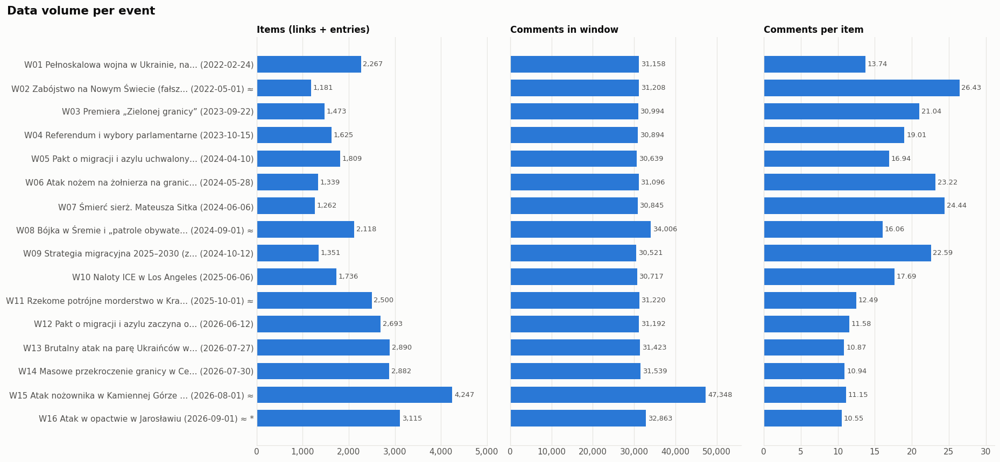

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 0.42 * len(EVENTS) + 1.2), sharey=True)
hbar(axes[0], summary['items'], LABELS, SERIES[0])
axes[0].set_title('Items (links + entries)')
hbar(axes[1], summary['comments'], LABELS, SERIES[0])
axes[1].set_title('Comments in window')
hbar(axes[2], summary['comments_per_item'], LABELS, SERIES[0], fmt='{:.2f}')
axes[2].set_title('Comments per item')
for ax in axes[:2]:
    ax.xaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
fig.suptitle('Data volume per event', x=0.01, ha='left')
fig.tight_layout()
savefig(fig, '01_volume_per_event')

Event sizes reflect both the event and the collection: windows that overlap a heavily collected period, or events that
drew big Wykop threads, dominate raw counts. The following sections therefore also use **shares** and **per-day**
values. ≈ marks events dated only to a month, \* windows that are not finished in the data.

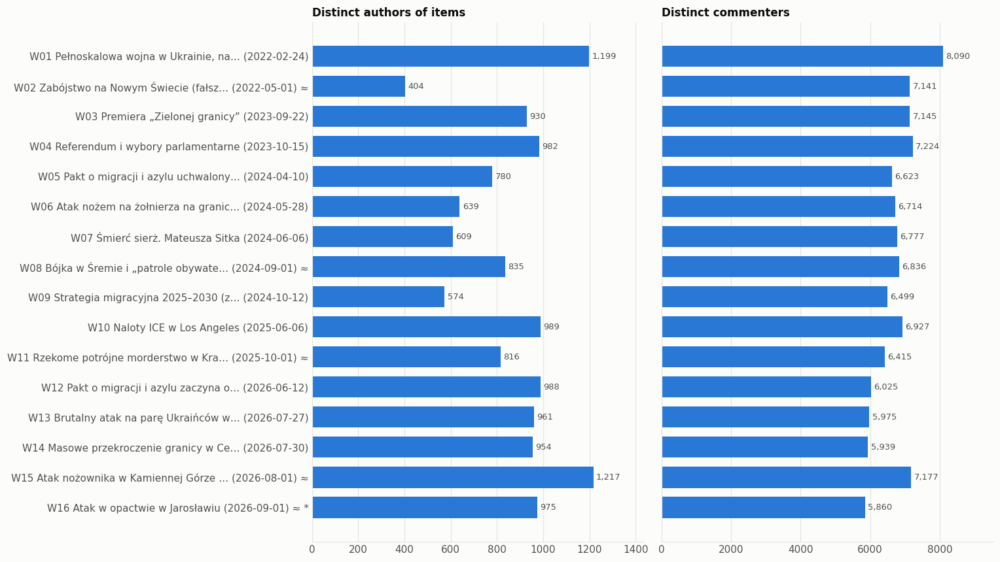

In [7]:
# Unique authors: items vs comments
fig, axes = plt.subplots(1, 2, figsize=(14, 0.42 * len(EVENTS) + 1.2), sharey=True)
hbar(axes[0], summary['item_authors'], LABELS, SERIES[0])
axes[0].set_title('Distinct authors of items')
hbar(axes[1], summary['commenters'], LABELS, SERIES[0])
axes[1].set_title('Distinct commenters')
fig.tight_layout()
savefig(fig, '02_authors_per_event')

exclusion_reason,outside_window,bot,total
event,,,
W01,383,1,384
W02,115,1,116
W03,87,235,322
W04,134,255,389
W05,354,324,678
W06,142,265,407
W07,265,260,525
W08,217,236,453
W09,86,225,311


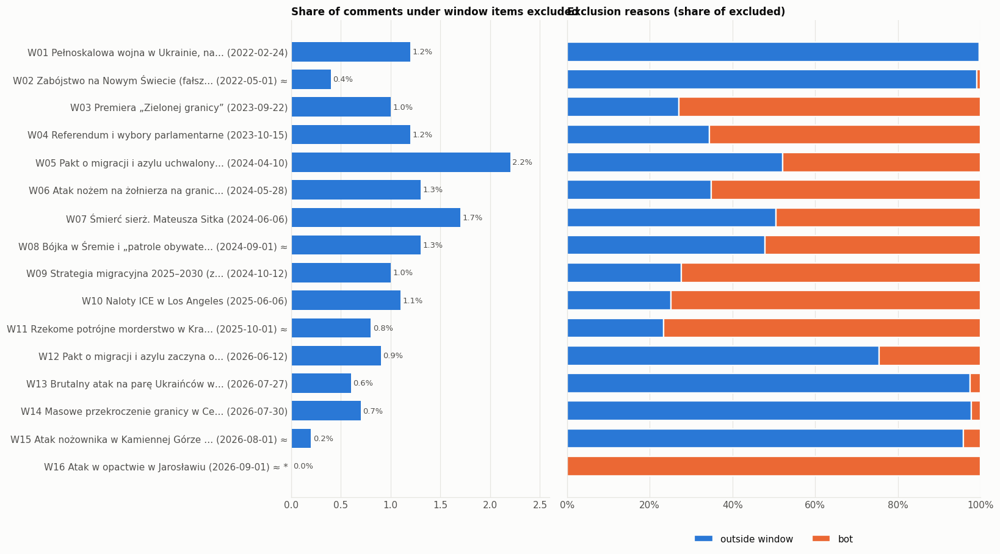

In [8]:
# Why were comments excluded?
reasons = (excluded.groupby(['event', 'exclusion_reason']).size().unstack(fill_value=0)
           .reindex(EVENTS, fill_value=0))
reasons = reasons[reasons.sum().sort_values(ascending=False).index]
reason_share = reasons.div(reasons.sum(axis=1).replace(0, np.nan), axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 0.42 * len(EVENTS) + 1.6), sharey=True,
                         gridspec_kw={'width_ratios': [1, 1.6]})
hbar(axes[0], summary['excluded_%'], LABELS, SERIES[0], fmt='{:.1f}%')
axes[0].set_title('Share of comments under window items excluded')

left = np.zeros(len(EVENTS))
y = np.arange(len(EVENTS))
for i, r in enumerate(reason_share.columns):
    vals = reason_share[r].fillna(0).values
    axes[1].barh(y, vals, left=left, color=SERIES[i], height=0.7, edgecolor=SURFACE, linewidth=1.5, label=r.replace('_', ' '))
    left += vals
axes[1].set_xlim(0, 100)
axes[1].xaxis.set_major_formatter(mticker.PercentFormatter())
axes[1].grid(axis='y', visible=False)
axes[1].set_title('Exclusion reasons (share of excluded)')
axes[1].legend(loc='upper center', bbox_to_anchor=(0.5, -0.06), ncol=max(1, len(reasons.columns)))
fig.tight_layout()
savefig(fig, '03_exclusions')
reasons.assign(total=reasons.sum(axis=1))

## 3. Volume over time

All timelines use `relative_day` (days from `t0_from`; 0 = event day, Europe/Warsaw). The dashed line marks day 0,
the darker band an uncertain event period (≈), the light shading the *after* phase; hatched days are not yet in the
data (\*). Y-axes are independent per panel because event sizes differ a lot.

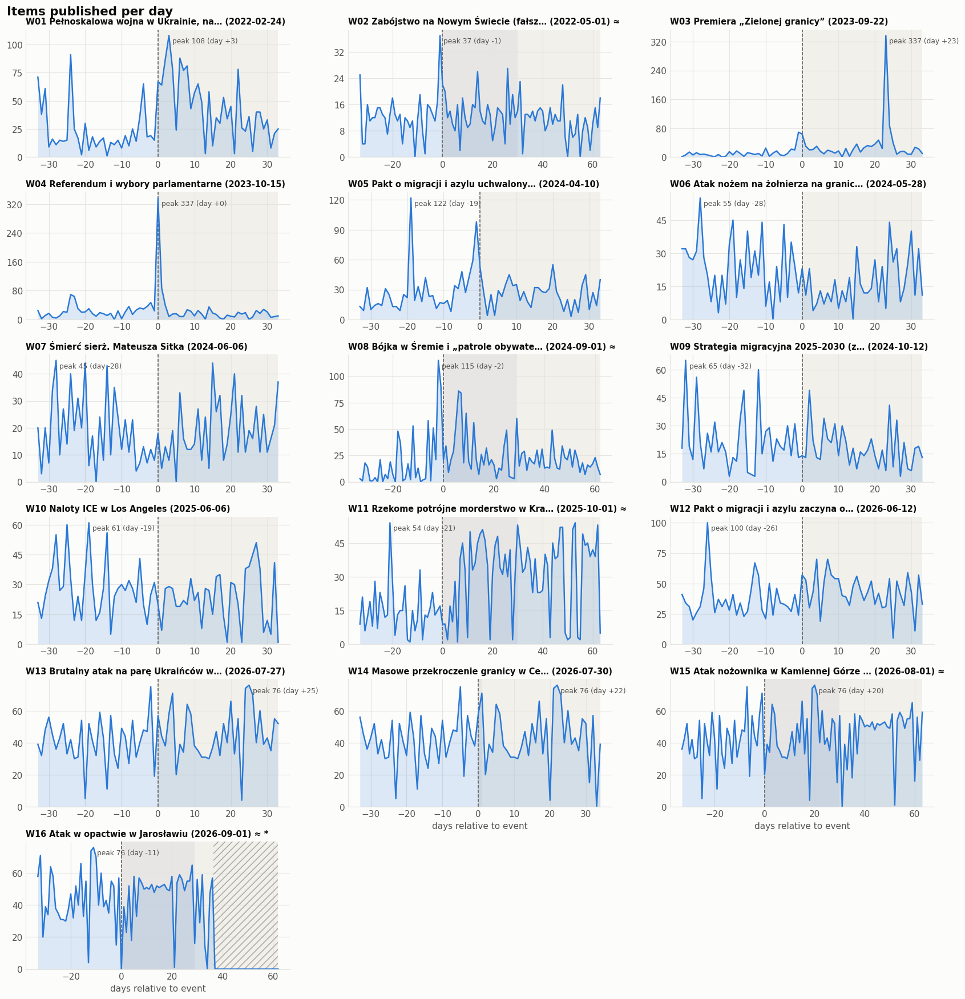

In [9]:
def daily_small_multiples(column, title, color=SERIES[0]):
    fig, axes = small_multiples(len(EVENTS))
    for ax, e in zip(axes, EVENTS):
        d = daily[daily['event'] == e].sort_values('relative_day')
        x, v = d['relative_day'].values, d[column].values
        mark_event_day(ax, e, x.max())
        ax.fill_between(x, v, color=color, alpha=0.15, lw=0)
        ax.plot(x, v, color=color, lw=1.6)
        if len(v) and np.nanmax(v) > 0:
            i = int(np.nanargmax(v))
            ax.annotate(f'peak {v[i]:,.0f} (day {x[i]:+d})', (x[i], v[i]), xytext=(4, -2),
                        textcoords='offset points', fontsize=8, color=TEXT_SECONDARY, va='top')
        ax.set_ylim(bottom=0)
        mark_not_collected(ax, e, x.max())
        ax.set_title(LABEL[e], fontsize=9.5)
        ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True, nbins=5))
        ax.yaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
    for ax in axes[-3:]:
        ax.set_xlabel('days relative to event')
    fig.suptitle(title, x=0.01, ha='left')
    fig.tight_layout()
    return fig

savefig(daily_small_multiples('items_published', 'Items published per day'), '04_daily_items')

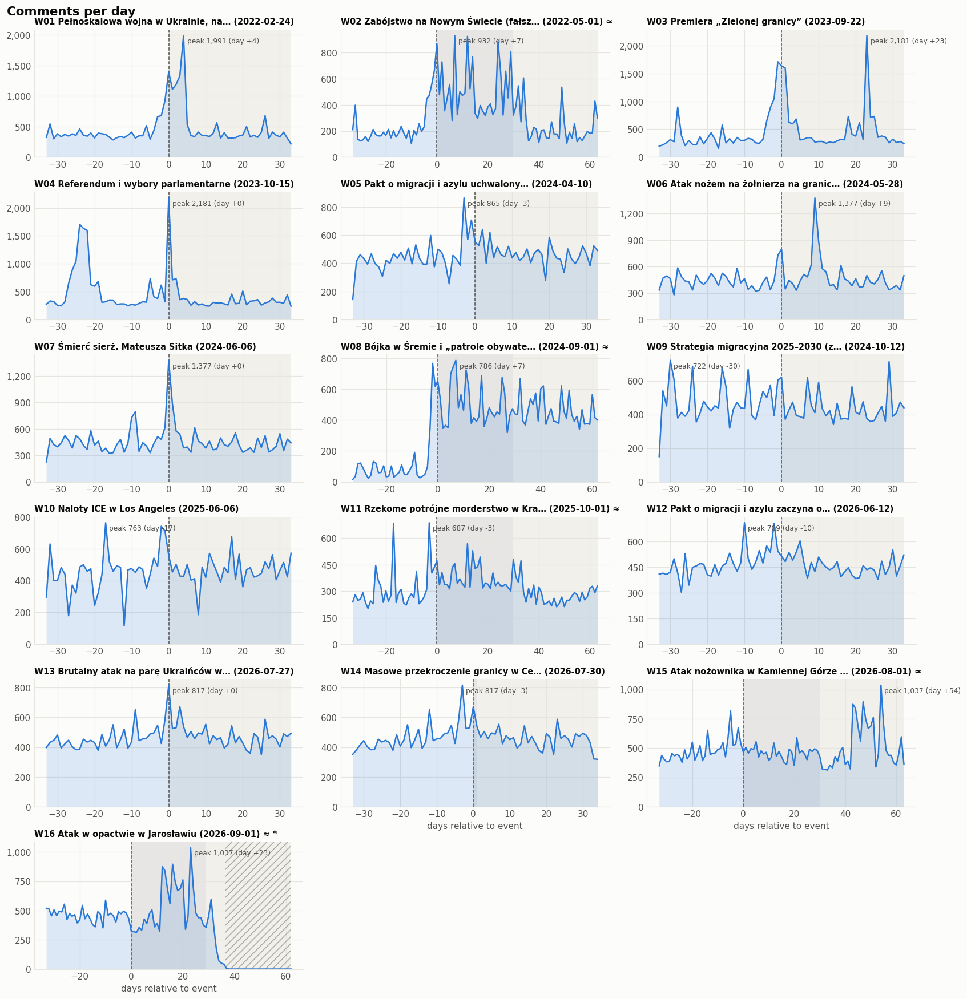

In [10]:
savefig(daily_small_multiples('comments', 'Comments per day'), '05_daily_comments')

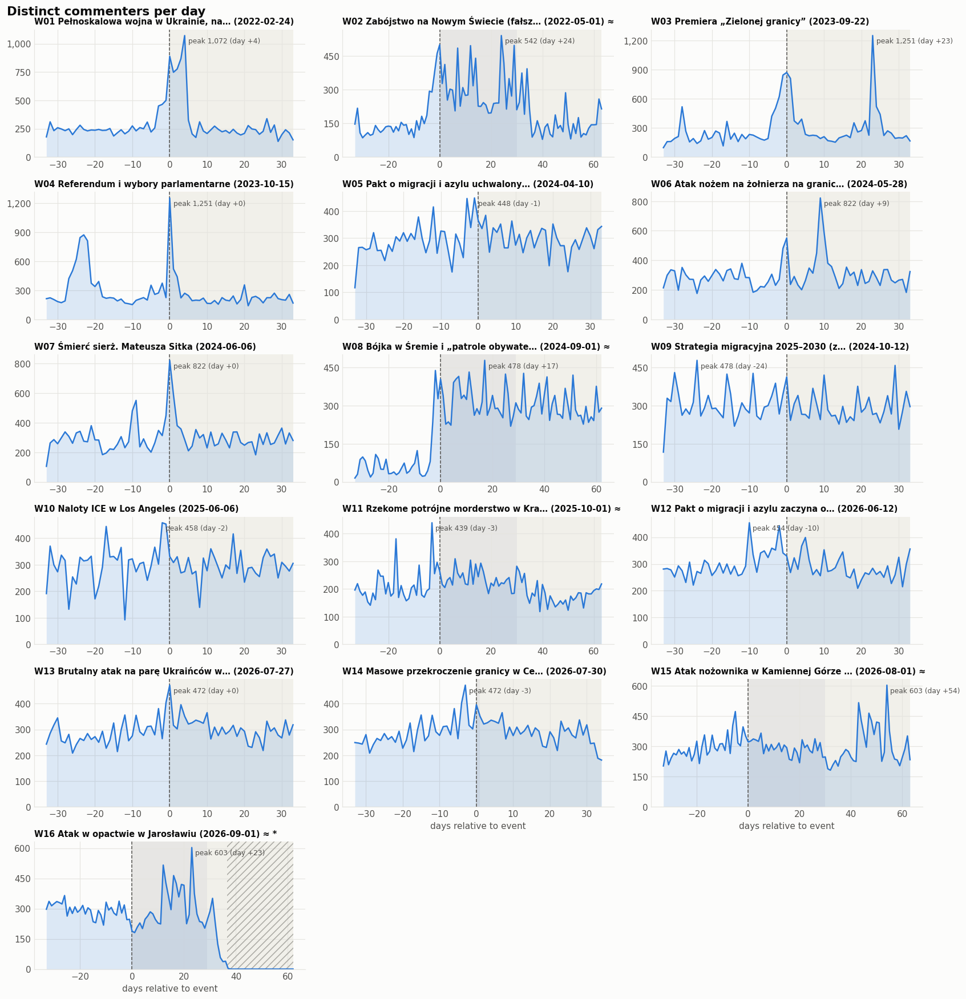

In [11]:
savefig(daily_small_multiples('unique_commenters', 'Distinct commenters per day'), '06_daily_commenters')

In [12]:
# Before vs after comparison (only fully collected days)
def phase_stats(e):
    d = daily_valid[daily_valid['event'] == e]
    b, a, d0 = d[d.phase == 'before'], d[d.phase == 'after'], d[d.phase == 'day_0']
    peak = d.loc[d['items_published'].idxmax()]
    first4 = d[d.relative_day.between(0, SPAN[e] + 3)]
    pct = lambda x, base: (x / base - 1) * 100 if base > 0 else np.nan
    return pd.Series({
        'items/day before': b['items_published'].mean(),
        'items/day event': d0['items_published'].mean(),
        'items/day after': a['items_published'].mean(),
        'items after vs before %': pct(a['items_published'].mean(), b['items_published'].mean()),
        'items day0..+3 vs before %': pct(first4['items_published'].mean(), b['items_published'].mean()),
        'peak day': int(peak['relative_day']),
        'comments/day before': b['comments'].mean(),
        'comments/day after': a['comments'].mean(),
        'comments after vs before %': pct(a['comments'].mean(), b['comments'].mean()),
    })

lift = pd.DataFrame({e: phase_stats(e) for e in EVENTS}).T
lift.index.name = 'event'
lift.round(1)

,items/day before,items/day event,items/day after,items after vs before %,items day0..+3 vs before %,peak day,comments/day before,comments/day after,comments after vs before %
event,,,,,,,,,
W01,22.7,67.0,44.0,94.1,259.6,3.0,400.5,501.3,25.2
W02,12.4,13.4,10.8,-13.0,7.5,-1.0,226.9,235.0,3.5
W03,10.6,64.0,32.1,201.4,217.3,23.0,408.6,481.1,17.7
W04,22.1,337.0,16.9,-23.6,432.3,0.0,529.3,340.8,-35.6
W05,28.4,52.0,24.8,-12.7,-5.0,-19.0,445.1,466.7,4.9
W06,23.5,23.0,16.4,-30.0,-35.0,-28.0,439.1,479.1,9.1
W07,18.8,18.0,18.9,0.3,-41.5,-28.0,447.3,445.7,-0.4
W08,18.8,28.2,19.8,5.3,48.3,-2.0,116.6,456.7,291.8
W09,22.3,14.0,18.2,-18.3,9.9,-32.0,472.9,433.2,-8.4


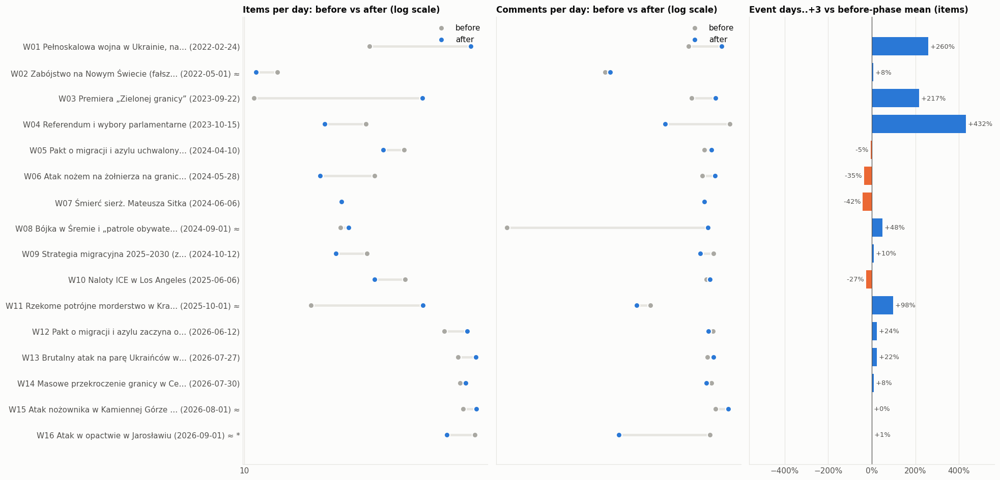

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 0.45 * len(EVENTS) + 1.5), sharey=True)
y = np.arange(len(EVENTS))
for ax, (b, a, title) in zip(axes[:2], [('items/day before', 'items/day after', 'Items per day'),
                                        ('comments/day before', 'comments/day after', 'Comments per day')]):
    bv, av = lift[b].values.astype(float), lift[a].values.astype(float)
    ax.hlines(y, np.minimum(bv, av), np.maximum(bv, av), color=GRID, lw=3)
    ax.scatter(bv, y, s=55, color=NEUTRAL, label='before', zorder=3, edgecolor=SURFACE, linewidth=1.5)
    ax.scatter(av, y, s=55, color=SERIES[0], label='after', zorder=3, edgecolor=SURFACE, linewidth=1.5)
    ax.set_xscale('symlog', linthresh=1)
    ax.xaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
    ax.set_title(f'{title}: before vs after (log scale)')
    ax.grid(axis='y', visible=False)
    ax.legend(loc='upper right')
axes[0].set_yticks(y, LABELS)
axes[0].invert_yaxis() if not axes[0].yaxis_inverted() else None

ch = lift['items day0..+3 vs before %'].astype(float).values
axes[2].barh(y, np.nan_to_num(ch), color=np.where(ch >= 0, POS, NEG), height=0.7)
axes[2].axvline(0, color=TEXT_SECONDARY, lw=0.8)
for yi, v in zip(y, ch):
    if pd.notna(v):
        axes[2].text(v, yi, f' {v:+.0f}% ', va='center', ha='left' if v >= 0 else 'right', fontsize=8.5, color=TEXT_SECONDARY)
axes[2].set_title('Event days..+3 vs before-phase mean (items)')
axes[2].grid(axis='y', visible=False)
axes[2].xaxis.set_major_formatter(mticker.PercentFormatter())
pad = np.nanmax(np.abs(ch)) * 1.3 if np.isfinite(ch).any() else 10
axes[2].set_xlim(min(-10, -pad if np.nanmin(ch) < 0 else -10), pad)
fig.tight_layout()
savefig(fig, '07_before_after')

## 4. Keywords

`matched_keywords` lists the topic-dictionary entries an item matched: plain names are the main keywords (HASLA),
`UA:` Ukraine patterns, `REF:` refugee / benefit terms and `POL:` political terms. An item can match many entries.

### 4.1 Which keywords dominate overall?

50 dictionary entries matched at least one item in the windows.


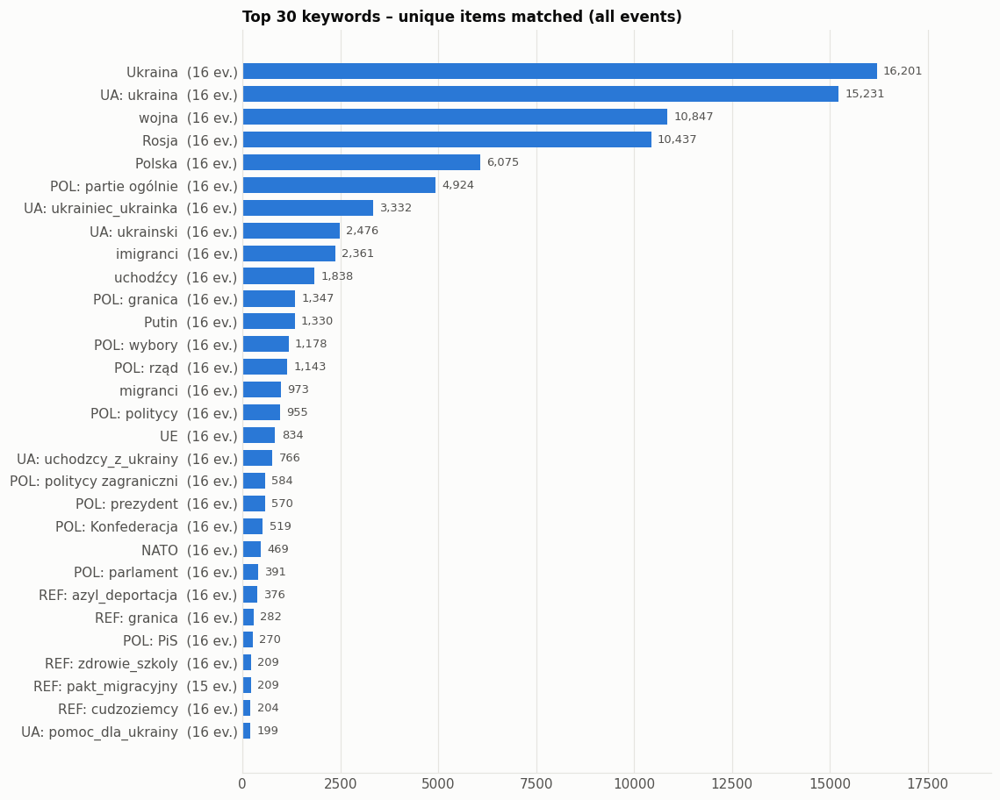

In [14]:
kw_unique = kw.drop_duplicates(['item_id', 'keyword'])            # each item once, whatever the event
kw_total = kw_unique['keyword'].value_counts()
kw_events = kw.groupby('keyword')['event'].nunique()

fig, ax = plt.subplots(figsize=(10, 0.3 * min(30, len(kw_total)) + 1))
top = kw_total.head(30)
hbar(ax, top, [f'{k}  ({kw_events[k]} ev.)' for k in top.index])
ax.set_title('Top 30 keywords – unique items matched (all events)')
savefig(fig, '08_keywords_global')
print(f'{len(kw_total)} dictionary entries matched at least one item in the windows.')

### 4.2 Keyword profile of each event

Share of an event's items that match the keyword (%). Normalising per event makes small and large events comparable.

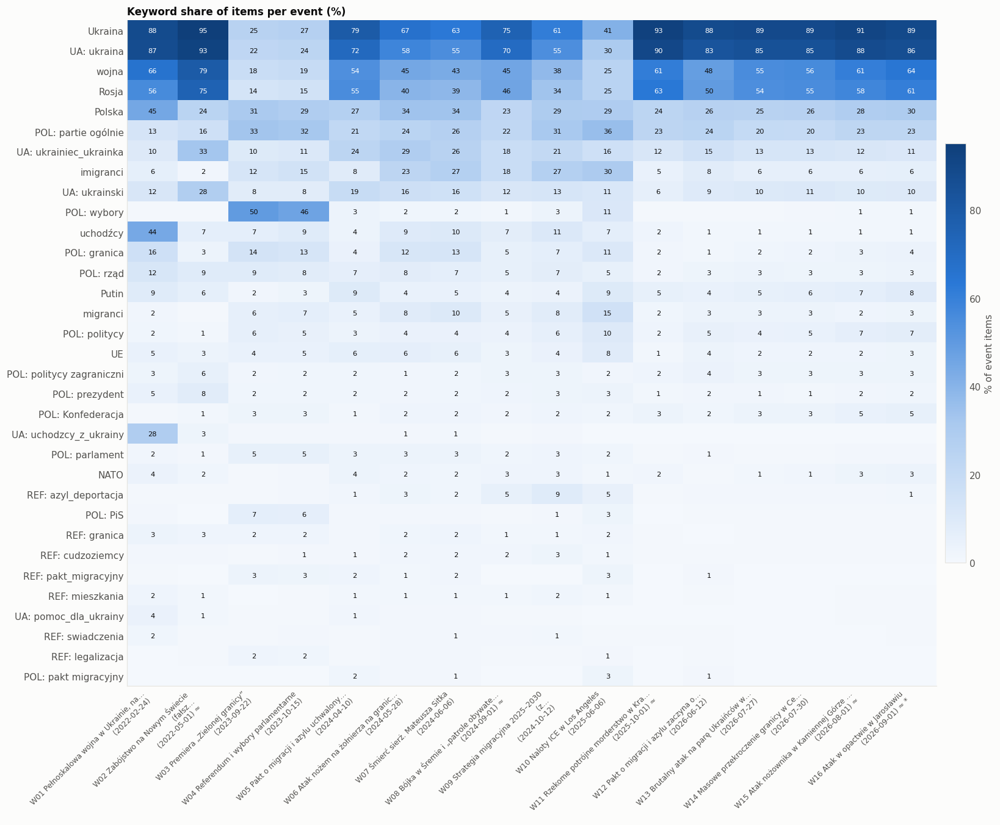

In [15]:
kw_share = (kw.groupby(['keyword', 'event'])['item_id'].nunique().unstack(fill_value=0)
            .reindex(columns=EVENTS, fill_value=0)
            .div(summary['items'], axis=1) * 100)
kw_share = kw_share.loc[kw_share.mean(axis=1).sort_values(ascending=False).index]
kw_share = kw_share[kw_share.max(axis=1) >= 2]          # hide entries that never reach 2 %

fig, ax = plt.subplots(figsize=(15, 0.3 * len(kw_share) + 2.5))
im = ax.imshow(kw_share.values, aspect='auto', cmap=SEQ, vmin=0)
ax.set_yticks(range(len(kw_share)), kw_share.index)
ax.set_xticks(range(len(EVENTS)), [l.replace(' (', '\n(') for l in LABELS], rotation=45, ha='right', fontsize=8)
ax.grid(False)
vmax = kw_share.values.max()
for i in range(kw_share.shape[0]):
    for j in range(kw_share.shape[1]):
        v = kw_share.iat[i, j]
        if v >= 1:
            ax.text(j, i, f'{v:.0f}', ha='center', va='center', fontsize=7.5, color='white' if v > vmax * 0.55 else TEXT_PRIMARY)
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01)
cb.set_label('% of event items')
ax.set_title('Keyword share of items per event (%)')
fig.tight_layout()
savefig(fig, '09_keyword_event_heatmap')

In [16]:
# Top keywords per event as a compact table
top_kw_table = pd.DataFrame({
    LABEL[e]: [f'{k} ({v:.0f}%)' for k, v in kw_share[e].sort_values(ascending=False).head(10).items()]
    for e in EVENTS
}, index=pd.RangeIndex(1, 11, name='rank')).T
top_kw_table

rank,1,2,3,4,5,6,7,8,9,10
"W01 Pełnoskalowa wojna w Ukrainie, na… (2022-02-24)",Ukraina (88%),UA: ukraina (87%),wojna (66%),Rosja (56%),Polska (45%),uchodźcy (44%),UA: uchodzcy_z_ukrainy (28%),POL: granica (16%),POL: partie ogólnie (13%),POL: rząd (12%)
W02 Zabójstwo na Nowym Świecie (fałsz… (2022-05-01) ≈,Ukraina (95%),UA: ukraina (93%),wojna (79%),Rosja (75%),UA: ukrainiec_ukrainka (33%),UA: ukrainski (28%),Polska (24%),POL: partie ogólnie (16%),POL: rząd (9%),POL: prezydent (8%)
W03 Premiera „Zielonej granicy” (2023-09-22),POL: wybory (50%),POL: partie ogólnie (33%),Polska (31%),Ukraina (25%),UA: ukraina (22%),wojna (18%),POL: granica (14%),Rosja (14%),imigranci (12%),UA: ukrainiec_ukrainka (10%)
W04 Referendum i wybory parlamentarne (2023-10-15),POL: wybory (46%),POL: partie ogólnie (32%),Polska (29%),Ukraina (27%),UA: ukraina (24%),wojna (19%),imigranci (15%),Rosja (15%),POL: granica (13%),UA: ukrainiec_ukrainka (11%)
W05 Pakt o migracji i azylu uchwalony… (2024-04-10),Ukraina (79%),UA: ukraina (72%),Rosja (55%),wojna (54%),Polska (27%),UA: ukrainiec_ukrainka (24%),POL: partie ogólnie (21%),UA: ukrainski (19%),Putin (9%),imigranci (8%)
W06 Atak nożem na żołnierza na granic… (2024-05-28),Ukraina (67%),UA: ukraina (58%),wojna (45%),Rosja (40%),Polska (34%),UA: ukrainiec_ukrainka (29%),POL: partie ogólnie (24%),imigranci (23%),UA: ukrainski (16%),POL: granica (12%)
W07 Śmierć sierż. Mateusza Sitka (2024-06-06),Ukraina (63%),UA: ukraina (55%),wojna (43%),Rosja (39%),Polska (34%),imigranci (27%),POL: partie ogólnie (26%),UA: ukrainiec_ukrainka (26%),UA: ukrainski (16%),POL: granica (13%)
W08 Bójka w Śremie i „patrole obywate… (2024-09-01) ≈,Ukraina (75%),UA: ukraina (70%),Rosja (46%),wojna (45%),Polska (23%),POL: partie ogólnie (22%),imigranci (18%),UA: ukrainiec_ukrainka (18%),UA: ukrainski (12%),uchodźcy (7%)
W09 Strategia migracyjna 2025–2030 (z… (2024-10-12),Ukraina (61%),UA: ukraina (55%),wojna (38%),Rosja (34%),POL: partie ogólnie (31%),Polska (29%),imigranci (27%),UA: ukrainiec_ukrainka (21%),UA: ukrainski (13%),uchodźcy (11%)
W10 Naloty ICE w Los Angeles (2025-06-06),Ukraina (41%),POL: partie ogólnie (36%),UA: ukraina (30%),imigranci (30%),Polska (29%),Rosja (25%),wojna (25%),UA: ukrainiec_ukrainka (16%),migranci (15%),UA: ukrainski (11%)


### 4.3 Per-event keyword timelines

For every event: **top-left** – most frequent keywords (items matched, % of event items), **top-right** – items per
day for the 5 most frequent keywords, **bottom** – heatmap of items per day for the top 15 keywords. Change
`TOP_LINES`, `TOP_HEAT` or `SMOOTH` (rolling-mean window in days, 1 = raw) to adjust.

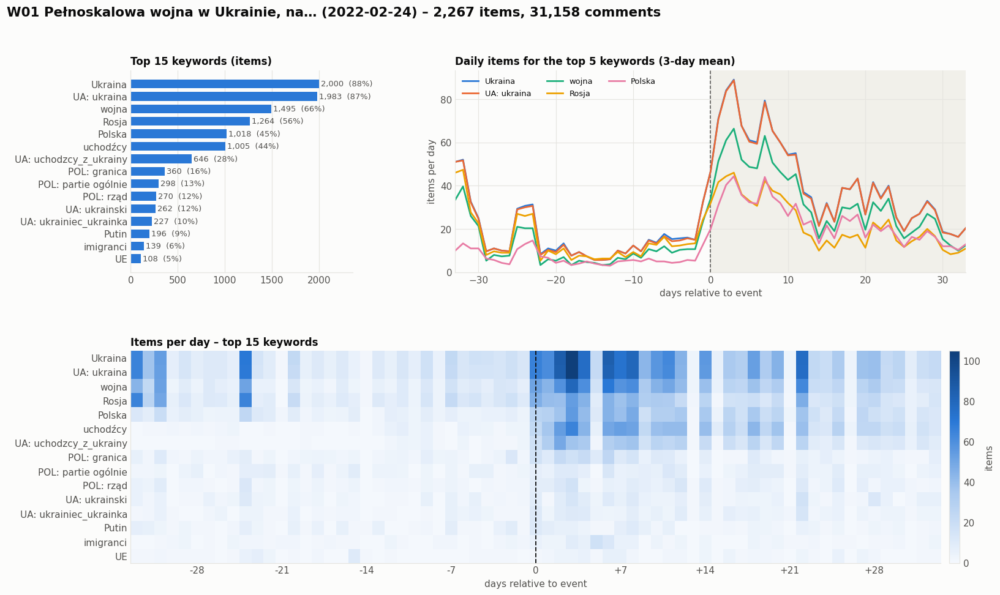

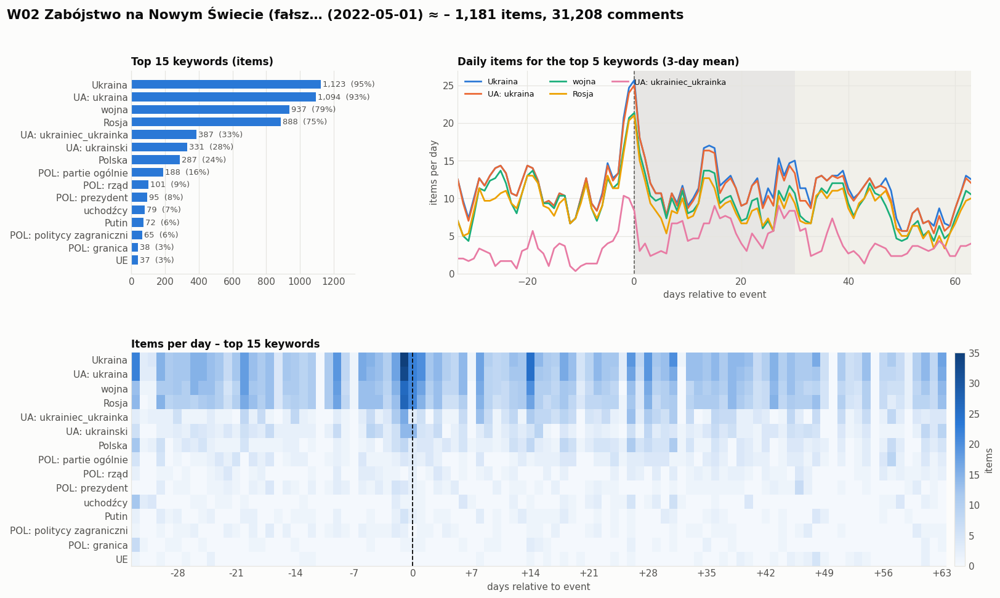

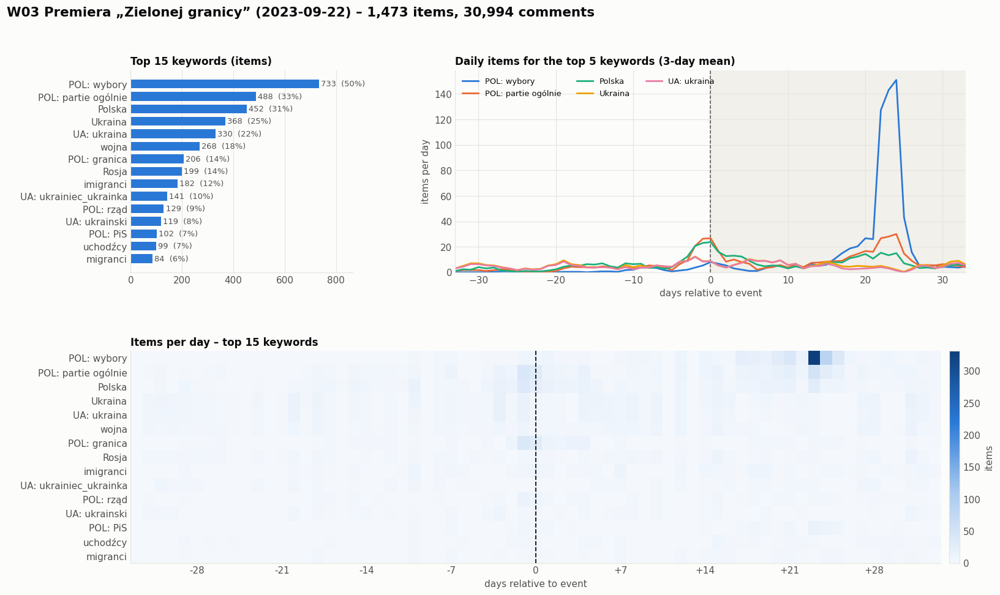

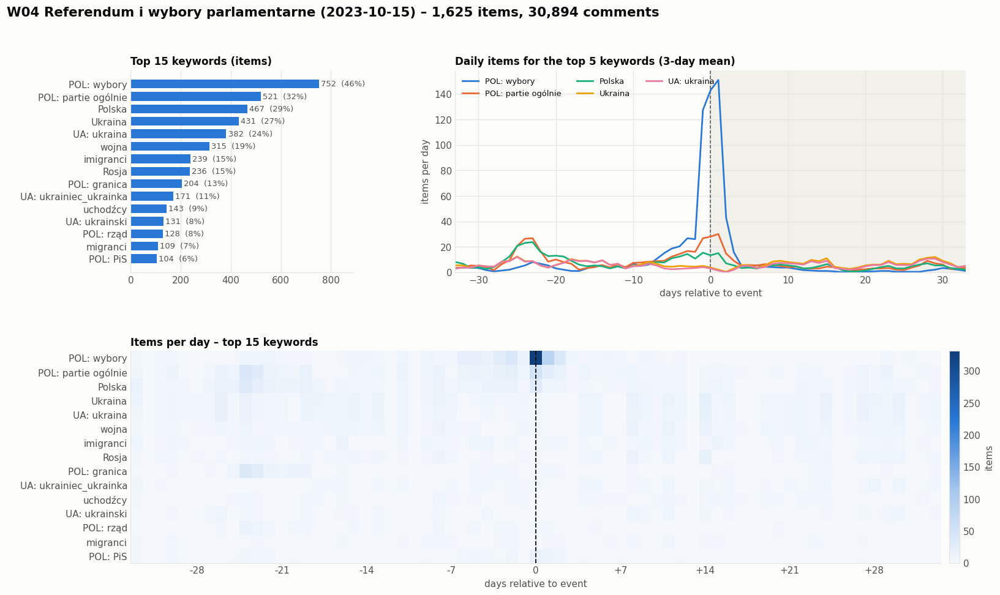

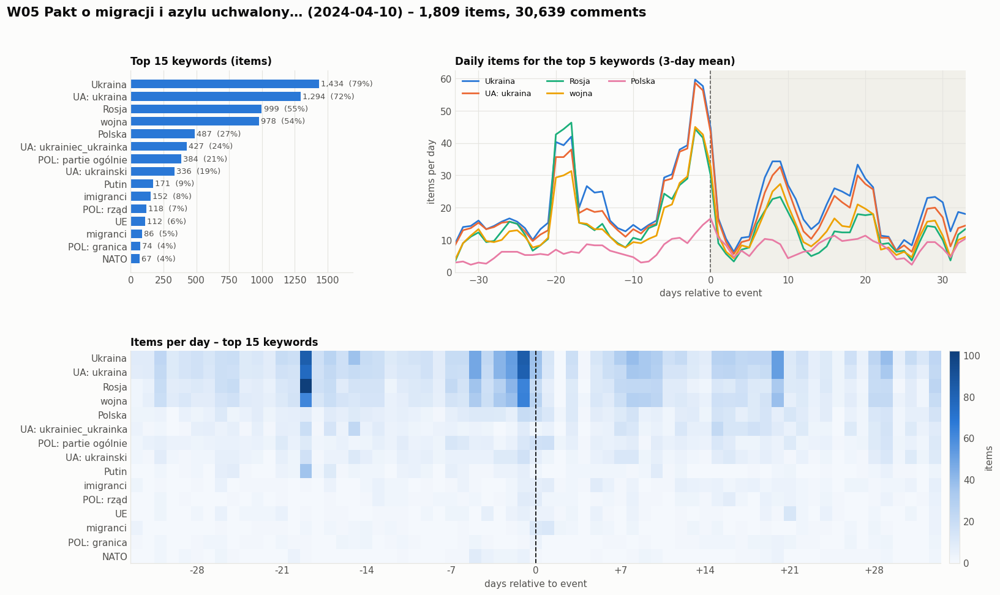

...

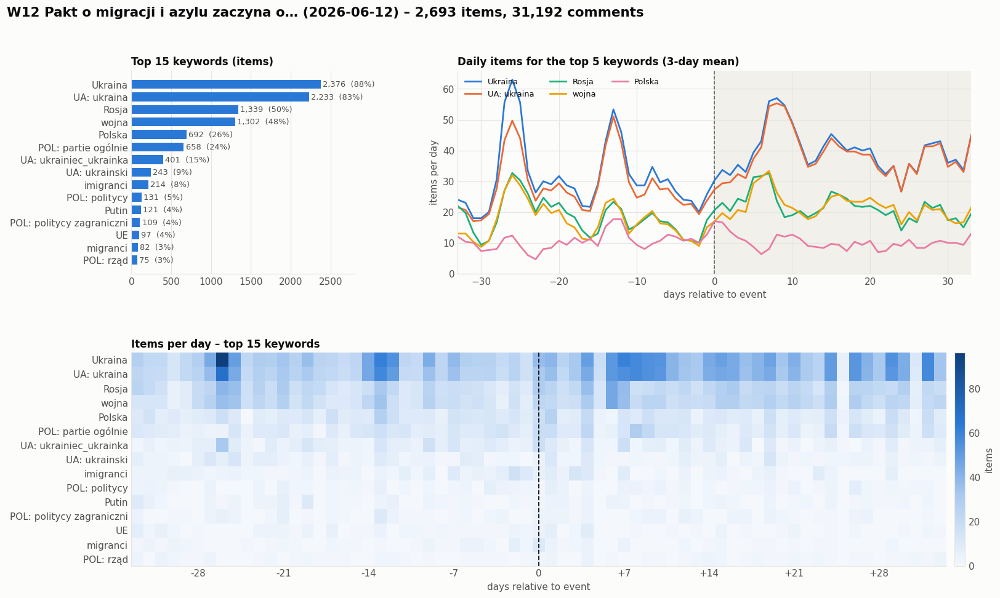

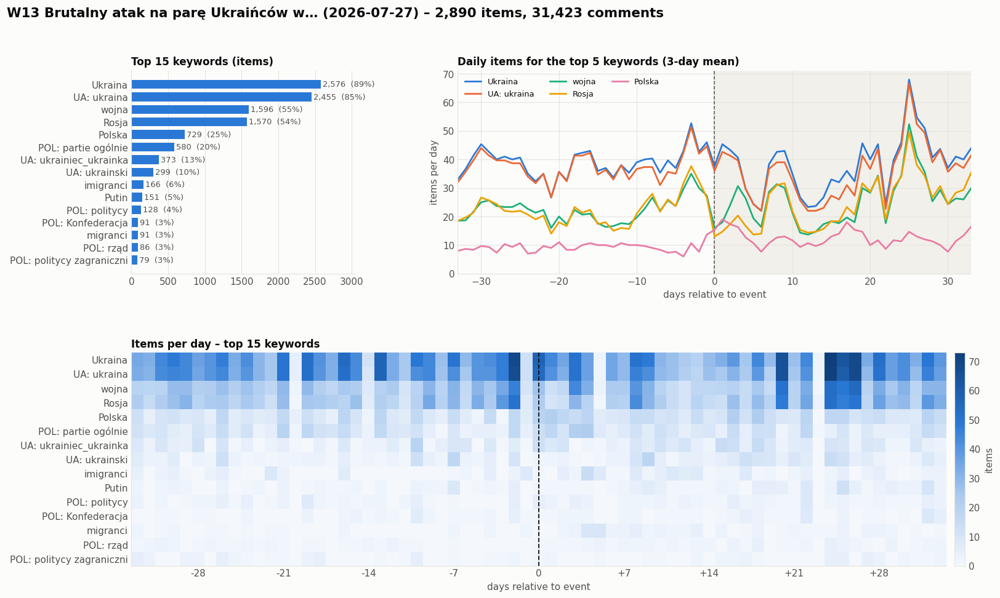

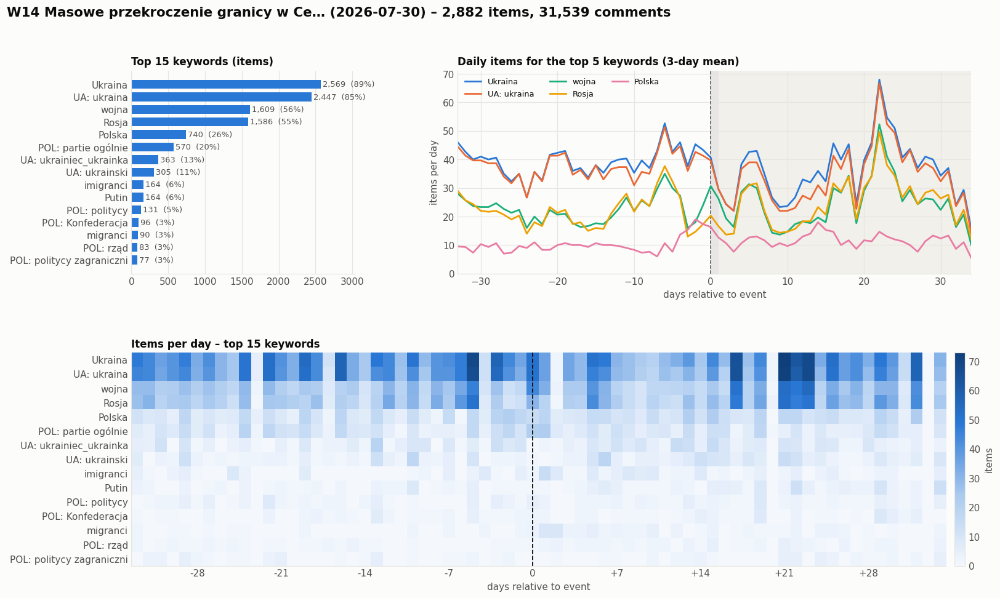

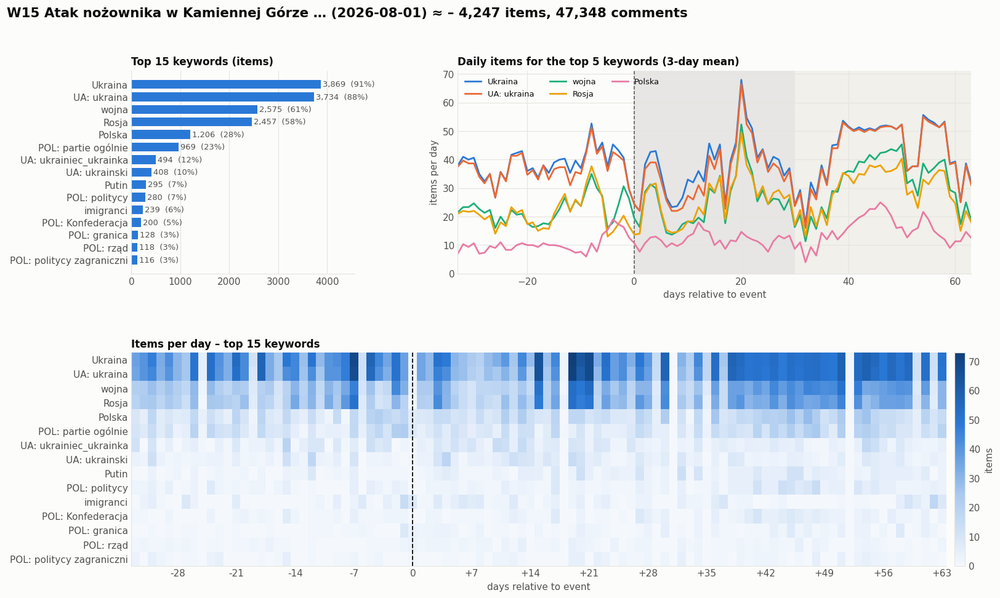

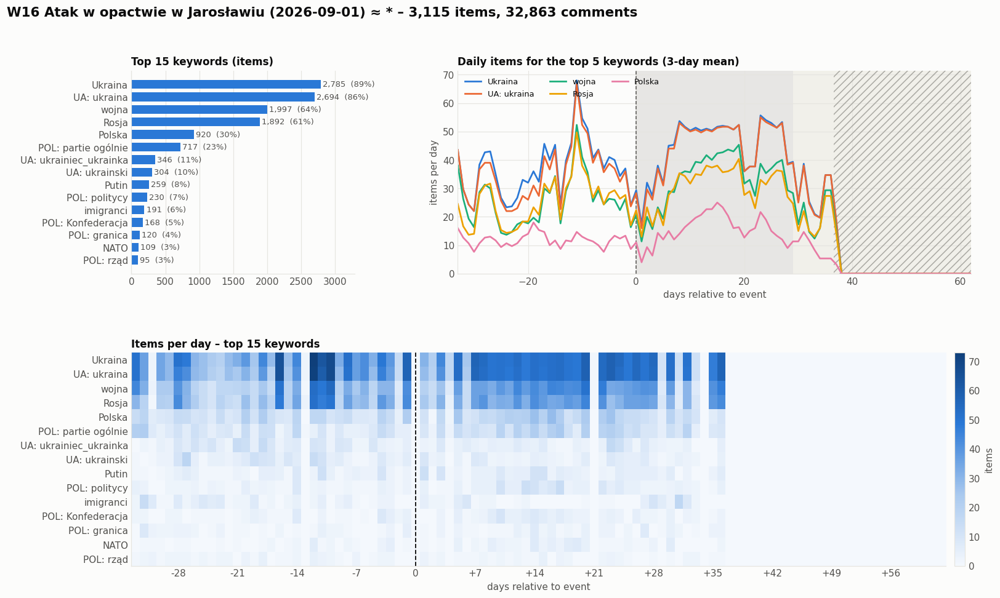

In [17]:
TOP_BAR, TOP_LINES, TOP_HEAT, SMOOTH = 15, 5, 15, 3

def plot_event_keywords(event):
    k = kw[kw['event'] == event]
    if k.empty:
        print(f'{LABEL[event]}: no keyword matches'); return
    counts = k['keyword'].value_counts()
    days = np.arange(DAY_RANGE.loc[event, 'min'], DAY_RANGE.loc[event, 'max'] + 1)
    by_day = k.groupby(['relative_day', 'keyword']).size().unstack(fill_value=0).reindex(days, fill_value=0)
    n_items = summary.loc[event, 'items']

    fig = plt.figure(figsize=(16, 9.5))
    gs = fig.add_gridspec(2, 2, width_ratios=[1, 2.3], height_ratios=[1, 1.05], hspace=0.38, wspace=0.28)
    ax_bar, ax_line, ax_heat = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[1, :])

    top = counts.head(TOP_BAR)
    hbar(ax_bar, top, color=SERIES[0])
    for t, (name, v) in zip(ax_bar.texts, top.items()):
        t.set_text(f'{v:,.0f}  ({v / n_items * 100:.0f}%)')
    ax_bar.set_title(f'Top {len(top)} keywords (items)')

    mark_event_day(ax_line, event, days.max())
    for i, name in enumerate(counts.index[:TOP_LINES]):
        s = by_day[name].rolling(SMOOTH, center=True, min_periods=1).mean()
        ax_line.plot(days, s, color=SERIES[i], lw=1.8, label=name)
    ax_line.set_ylim(bottom=0)
    mark_not_collected(ax_line, event, days.max())
    ax_line.set_xlim(days.min(), days.max())
    ax_line.set_xlabel('days relative to event')
    ax_line.set_ylabel('items per day')
    ax_line.legend(loc='upper left', ncol=min(TOP_LINES, 3), fontsize=8.5)
    ax_line.set_title(f'Daily items for the top {TOP_LINES} keywords' + (f' ({SMOOTH}-day mean)' if SMOOTH > 1 else ''))

    heat_kw = counts.index[:TOP_HEAT]
    M = by_day[heat_kw].T
    im = ax_heat.imshow(M.values, aspect='auto', cmap=SEQ, interpolation='nearest', vmin=0)
    ax_heat.set_yticks(range(len(heat_kw)), heat_kw)
    ticks = [i for i, d in enumerate(days) if d % 7 == 0]
    ax_heat.set_xticks(ticks, [f'{days[i]:+d}' if days[i] else '0' for i in ticks])
    ax_heat.axvline(list(days).index(0), color=TEXT_PRIMARY, lw=1.2, ls='--')
    ax_heat.grid(False)
    ax_heat.set_xlabel('days relative to event')
    ax_heat.set_title(f'Items per day – top {len(heat_kw)} keywords')
    fig.colorbar(im, ax=ax_heat, fraction=0.02, pad=0.01).set_label('items')

    fig.suptitle(f'{LABEL[event]} – {n_items:,} items, {summary.loc[event, "comments"]:,} comments', x=0.01, ha='left')
    savefig(fig, f'10_keywords_{event}')
    plt.show()

for e in EVENTS:
    plot_event_keywords(e)

### 4.4 Which keywords gained share after the event?

Change in the share of items matching a keyword, *after* (event period included) vs *before*, in percentage points.
Only keywords with ≥ 10 matched items in the event are considered; small events are noisy.

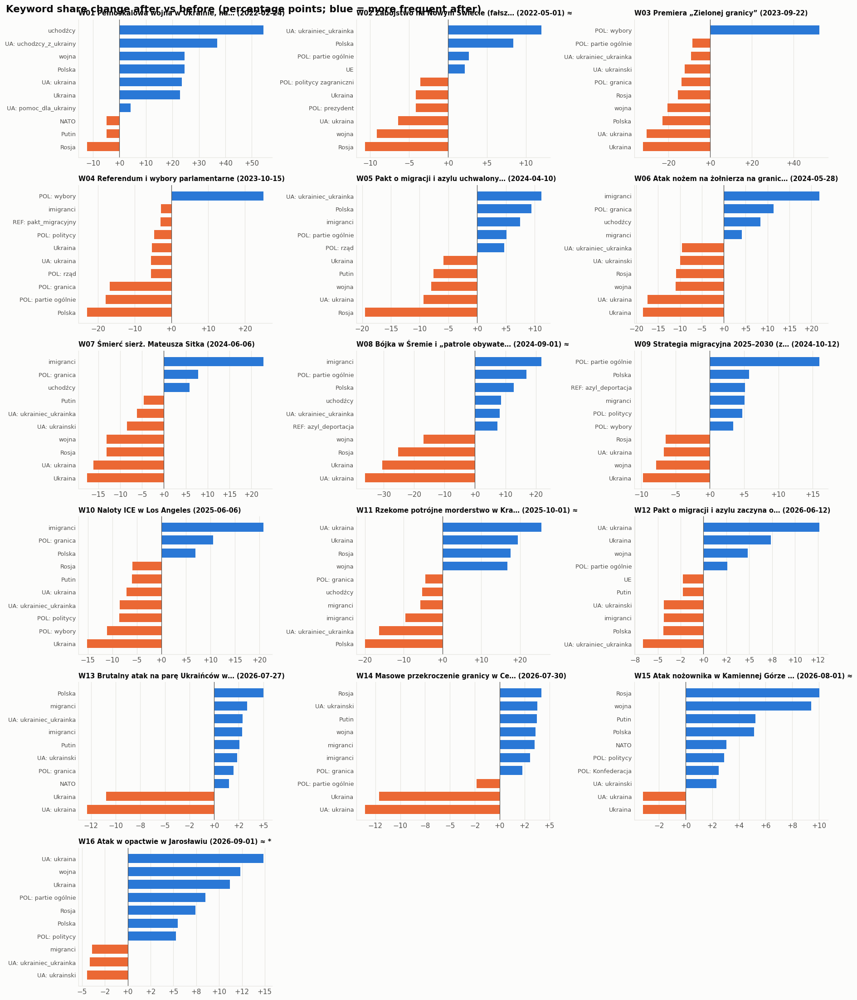

In [18]:
MIN_ITEMS, TOP_SHIFT = 10, 10

def keyword_shift(e):
    p = posts[(posts['event'] == e) & (posts['relative_day'] <= LAST_DAY[e])]
    k = kw[(kw['event'] == e) & (kw['relative_day'] <= LAST_DAY[e])].assign(ph=lambda d: np.where(d['phase'] == 'before', 'before', 'after'))
    n_before, n_after = (p['phase'] == 'before').sum(), (p['phase'] != 'before').sum()
    counts = k.groupby(['keyword', 'ph'])['item_id'].nunique().unstack(fill_value=0)
    for col in ('before', 'after'):
        if col not in counts:
            counts[col] = 0
    counts = counts[counts.sum(axis=1) >= MIN_ITEMS]
    shift = counts['after'] / max(n_after, 1) * 100 - counts['before'] / max(n_before, 1) * 100
    return shift.reindex(shift.abs().sort_values(ascending=False).index).head(TOP_SHIFT)

fig, axes = small_multiples(len(EVENTS), ncols=3, w=5.6, h=3.4)
shifts = {}
for ax, e in zip(axes, EVENTS):
    s = keyword_shift(e).sort_values()
    shifts[e] = s
    ax.barh(range(len(s)), s.values, color=np.where(s.values >= 0, POS, NEG), height=0.7)
    ax.set_yticks(range(len(s)), s.index, fontsize=8.5)
    ax.axvline(0, color=TEXT_SECONDARY, lw=0.8)
    ax.grid(axis='y', visible=False)
    ax.set_title(LABEL[e], fontsize=9.5)
    ax.xaxis.set_major_formatter(mticker.StrMethodFormatter('{x:+.0f}'))
fig.suptitle('Keyword share change after vs before (percentage points; blue = more frequent after)', x=0.01, ha='left')
fig.tight_layout()
savefig(fig, '11_keyword_shift')

### 4.5 Keyword co-occurrence

How often two keywords are matched by the same item (Jaccard index: items with both / items with either).

keyword      keyword               
Ukraina      UA: ukraina               94.0
wojna        Rosja                     66.7
UA: ukraina  wojna                     65.7
Ukraina      wojna                     62.8
UA: ukraina  Rosja                     62.0
Ukraina      Rosja                     59.3
uchodźcy     UA: uchodzcy_z_ukrainy    41.7
Ukraina      Polska                    25.5
UA: ukraina  Polska                    24.7
Polska       POL: partie ogólnie       23.9
Name: jaccard_%, dtype: float64

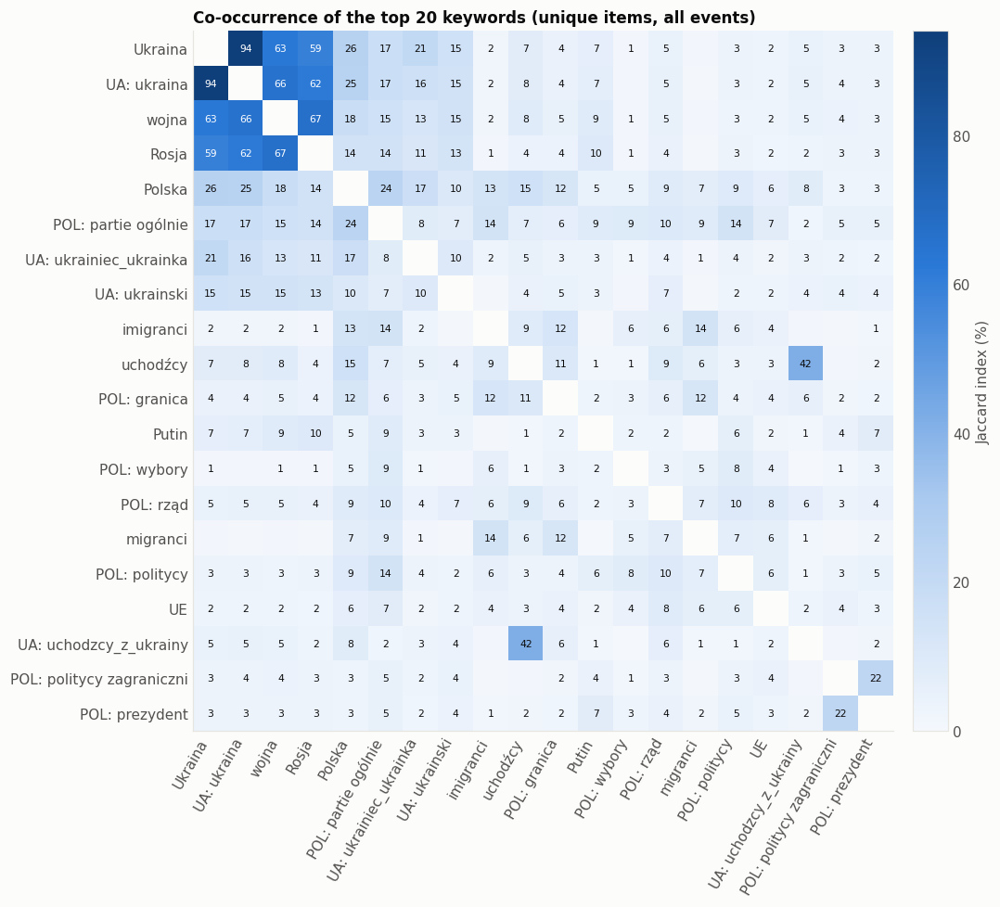

In [19]:
TOP_CO = 20
top_kw = kw_total.head(TOP_CO).index
sets = {k: set(kw_unique.loc[kw_unique['keyword'] == k, 'item_id']) for k in top_kw}
jac = pd.DataFrame(0.0, index=top_kw, columns=top_kw)
for a in top_kw:
    for b in top_kw:
        if a != b:
            jac.loc[a, b] = len(sets[a] & sets[b]) / len(sets[a] | sets[b]) * 100
mask = np.eye(len(top_kw), dtype=bool)

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(np.ma.masked_array(jac.values, mask), cmap=SEQ, vmin=0)
ax.set_xticks(range(len(top_kw)), top_kw, rotation=60, ha='right')
ax.set_yticks(range(len(top_kw)), top_kw)
ax.grid(False)
for i in range(len(top_kw)):
    for j in range(len(top_kw)):
        if i != j and jac.iat[i, j] >= 1:
            ax.text(j, i, f'{jac.iat[i, j]:.0f}', ha='center', va='center', fontsize=7,
                    color='white' if jac.iat[i, j] > jac.values.max() * 0.55 else TEXT_PRIMARY)
fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02).set_label('Jaccard index (%)')
ax.set_title(f'Co-occurrence of the top {TOP_CO} keywords (unique items, all events)')
fig.tight_layout()
savefig(fig, '12_keyword_cooccurrence')

pairs = (jac.where(np.triu(np.ones(jac.shape, dtype=bool), 1)).stack()
         .sort_values(ascending=False).head(10).round(1).rename('jaccard_%'))
pairs

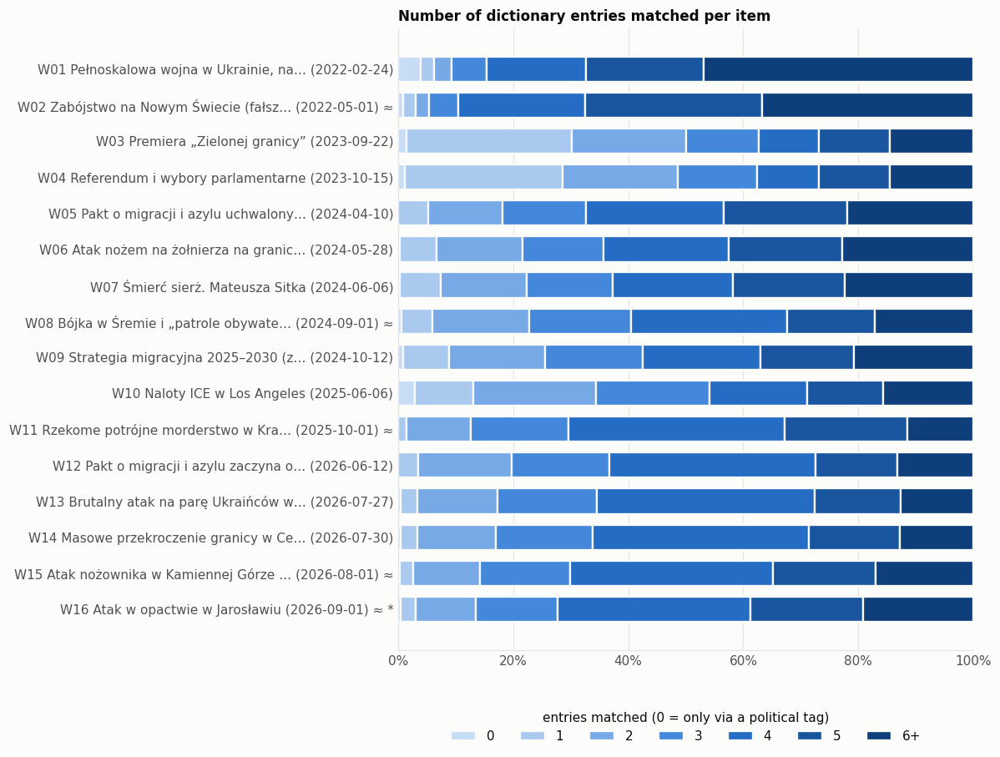

In [20]:
# How many dictionary entries does a single item match?
nk = posts.assign(n=posts['n_keywords'].clip(upper=6)).groupby(['event', 'n']).size().unstack(fill_value=0)
nk = nk.reindex(EVENTS).fillna(0)
nk = nk.div(nk.sum(axis=1), axis=0) * 100
cats = {i: str(i) for i in range(6)} | {6: '6+'}
seq_colors = [SEQ(x) for x in np.linspace(0.2, 1, nk.shape[1])]

fig, ax = plt.subplots(figsize=(11, 0.42 * len(EVENTS) + 1.6))
left = np.zeros(len(EVENTS))
for c, col in zip(nk.columns, seq_colors):
    ax.barh(range(len(EVENTS)), nk[c].values, left=left, color=col, height=0.7, edgecolor=SURFACE, linewidth=1.5, label=cats[c])
    left += nk[c].values
ax.set_yticks(range(len(EVENTS)), LABELS)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(mticker.PercentFormatter())
ax.grid(axis='y', visible=False)
ax.legend(title='entries matched (0 = only via a political tag)', loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=7)
ax.set_title('Number of dictionary entries matched per item')
fig.tight_layout()
savefig(fig, '13_keywords_per_item')

## 5. Slur-dictionary matches

Share of **Polish comments** that match at least one entry of the research slur / coded-term dictionary
(`matched_slurs`). A match is a flag for manual review, not a hate-speech label: some entries are ambiguous
(marked `*` in tables) and the matching ignores irony, quotes and negation.

,n,k,share_%,ci_lo_%,ci_hi_%,only_ambiguous_%
event,,,,,,
W01,29960,635,2.12,1.96,2.29,56.69
W02,29967,542,1.81,1.66,1.97,64.76
W03,29889,996,3.33,3.13,3.54,51.51
W04,29761,989,3.32,3.13,3.53,51.77
W05,29467,896,3.04,2.85,3.24,49.89
W06,29988,1058,3.53,3.33,3.74,51.98
W07,29759,1033,3.47,3.27,3.69,51.50
W08,32721,1305,3.99,3.78,4.21,54.56
W09,29435,1250,4.25,4.02,4.48,53.92


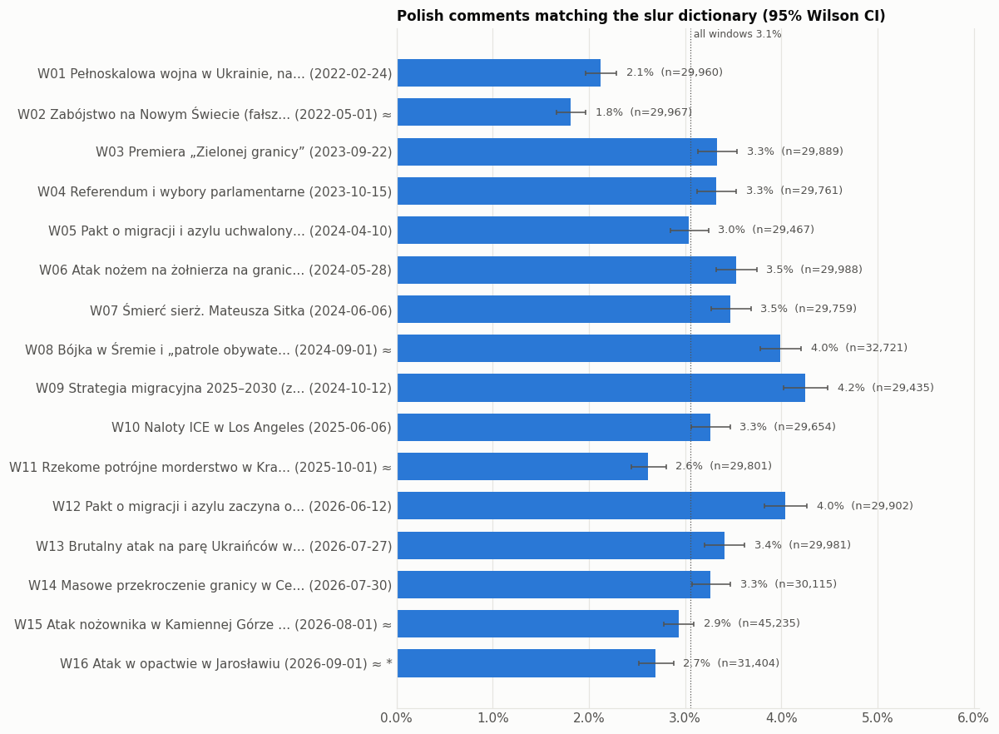

In [21]:
AMBIGUOUS = {'banderowcy', 'upaińcy / upowcy', 'rezuny', 'ukrainizacja', 'roszczeniowi', 'na socjalu', 'murzyni', 'bambusy',
             'asfalt', 'brudasy', 'ahmedy / mahomety', 'kebaby', 'lekarze i inżynierowie', 'multikulti', 'najeźdźcy / inwazja',
             'szarańcza', 'pasożyty', 'robactwo', 'dzicz / hołota', 'islamizacja', 'wielka wymiana', 'remigracja'}

sl = pl_comm.groupby('event')['has_slur'].agg(n='size', k='sum').reindex(EVENTS)
sl['share_%'] = sl['k'] / sl['n'] * 100
ci = [wilson(k, n) for k, n in zip(sl['k'], sl['n'])]
sl['ci_lo_%'], sl['ci_hi_%'] = [c[0] * 100 for c in ci], [c[1] * 100 for c in ci]
only_amb = pl_comm[pl_comm['has_slur']].assign(amb=lambda d: d['matched_slurs'].map(lambda L: all(t in AMBIGUOUS for t in L)))
sl['only_ambiguous_%'] = only_amb.groupby('event')['amb'].mean().reindex(EVENTS) * 100
overall = comments.drop_duplicates('comment_id')
overall = overall[overall['is_pl']]['has_slur'].mean() * 100

fig, ax = plt.subplots(figsize=(11, 0.42 * len(EVENTS) + 1.4))
y = np.arange(len(EVENTS))
ax.barh(y, sl['share_%'], color=SERIES[0], height=0.7)
ax.errorbar(sl['share_%'], y, xerr=[sl['share_%'] - sl['ci_lo_%'], sl['ci_hi_%'] - sl['share_%']], fmt='none', ecolor=TEXT_SECONDARY, capsize=2, lw=1)
for yi, (v, n) in enumerate(zip(sl['share_%'], sl['n'])):
    ax.text(sl['ci_hi_%'].iloc[yi] + 0.1, yi, f'{v:.1f}%  (n={n:,})', va='center', fontsize=8.5, color=TEXT_SECONDARY)
ax.axvline(overall, color=TEXT_SECONDARY, lw=0.8, ls=':')
ax.text(overall, -0.9, f' all windows {overall:.1f}%', fontsize=8, color=TEXT_SECONDARY)
ax.set_yticks(y, LABELS)
ax.invert_yaxis()
ax.grid(axis='y', visible=False)
ax.set_xlim(0, sl['ci_hi_%'].max() * 1.35)
ax.xaxis.set_major_formatter(mticker.PercentFormatter())
ax.set_title('Polish comments matching the slur dictionary (95% Wilson CI)')
fig.tight_layout()
savefig(fig, '14_slur_share_per_event')
sl.round(2)

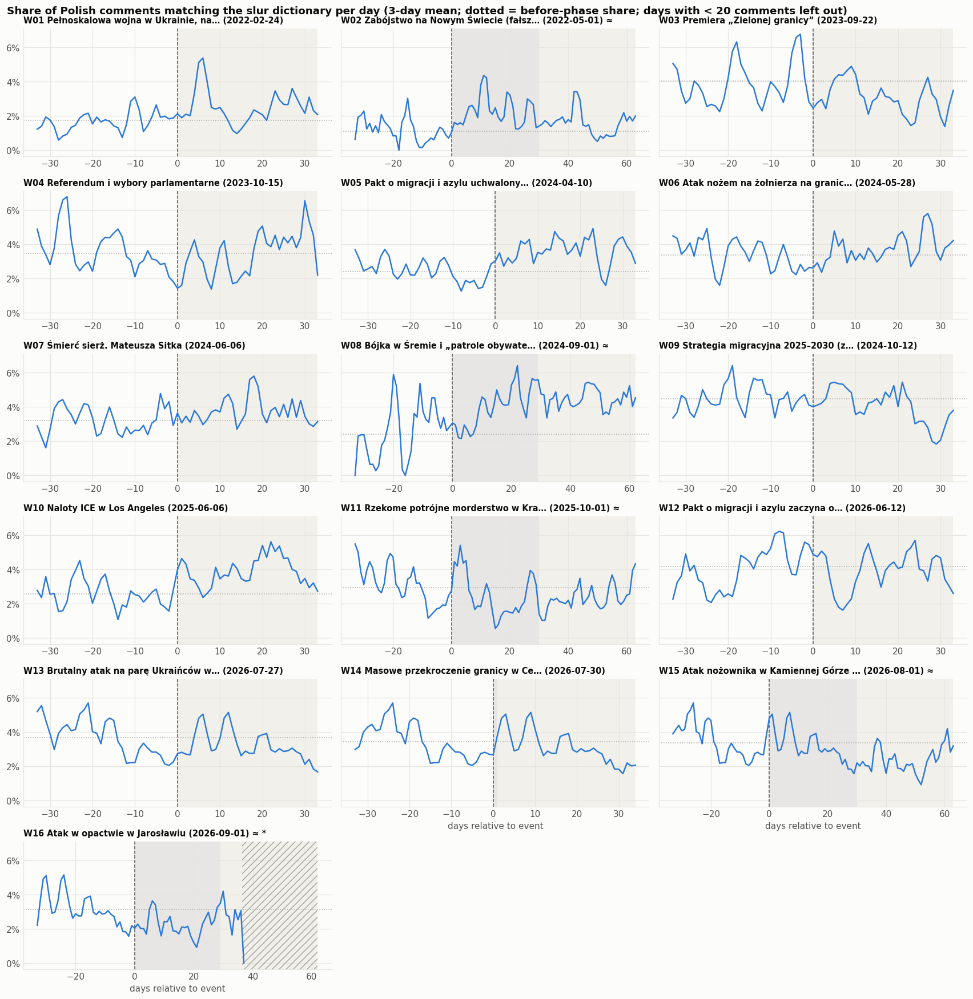

In [22]:
SLUR_SMOOTH = 3
fig, axes = small_multiples(len(EVENTS), sharey=True)
for ax, e in zip(axes, EVENTS):
    d = daily[daily['event'] == e].sort_values('relative_day')
    x = d['relative_day'].values
    s = (d['slur_share'] * 100).rolling(SLUR_SMOOTH, center=True, min_periods=1).mean()
    mark_event_day(ax, e, x.max())
    base = d.loc[d['relative_day'] < 0, 'slur_matches'].sum() / max(1, d.loc[d['relative_day'] < 0, 'comments_pl'].sum()) * 100
    ax.axhline(base, color=NEUTRAL, lw=1, ls=':')
    ax.plot(x, s, color=SERIES[0], lw=1.6)
    mark_not_collected(ax, e, x.max())
    ax.set_title(LABEL[e], fontsize=9.5)
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
for ax in axes[-3:]:
    ax.set_xlabel('days relative to event')
fig.suptitle(f'Share of Polish comments matching the slur dictionary per day ({SLUR_SMOOTH}-day mean; dotted = before-phase share; '
             f'days with < {MIN_DAY_N} comments left out)', x=0.01, ha='left', fontsize=12)
fig.tight_layout()
savefig(fig, '15_daily_slur_share')

,before_%,event..+3_%,after_%,comments_pl_before,comments_pl_after,change_pp
W01,1.75,1.90,2.47,12694.0,17266.0,0.16
W02,1.11,2.23,1.52,7175.0,22792.0,1.12
W03,4.03,2.69,2.93,13046.0,16843.0,-1.34
W04,3.49,2.06,3.35,16860.0,12901.0,-1.43
W05,2.42,3.23,3.59,14092.0,15375.0,0.81
W06,3.36,2.80,3.68,13975.0,16013.0,-0.56
W07,3.20,3.08,3.85,14232.0,15527.0,-0.13
W08,2.41,4.02,4.42,3693.0,29028.0,1.61
W09,4.48,4.16,4.00,15032.0,14403.0,-0.32
W10,2.56,4.46,3.88,14352.0,15302.0,1.90


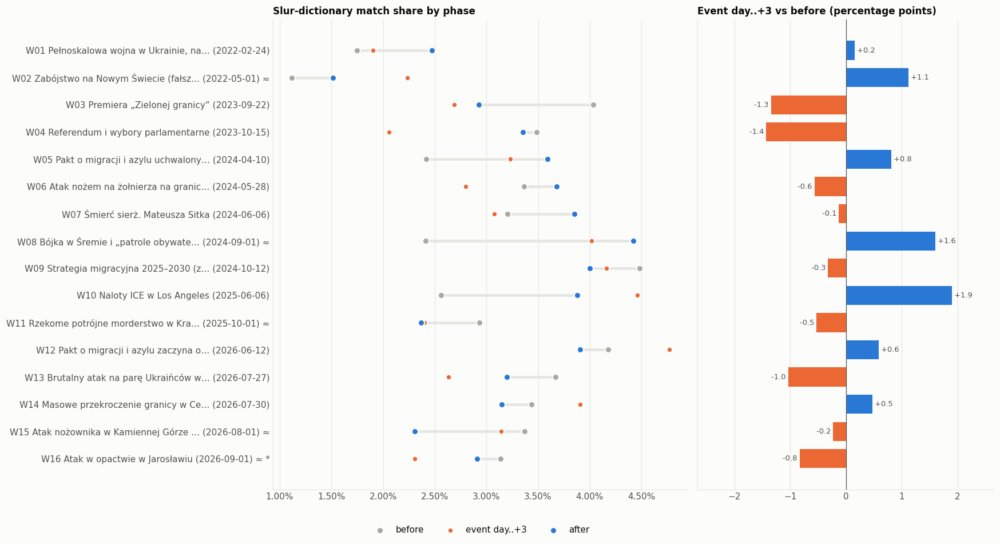

In [23]:
# Before vs after: pooled shares from fully collected days
def slur_phase(e):
    d = daily_valid[daily_valid['event'] == e]
    share = lambda m: d.loc[m, 'slur_matches'].sum() / max(1, d.loc[m, 'comments_pl'].sum()) * 100
    return pd.Series({
        'before_%': share(d['phase'] == 'before'),
        'event..+3_%': share(d['relative_day'].between(0, SPAN[e] + 3)),
        'after_%': share(d['phase'] == 'after'),
        'comments_pl_before': d.loc[d['phase'] == 'before', 'comments_pl'].sum(),
        'comments_pl_after': d.loc[d['phase'] != 'before', 'comments_pl'].sum(),
    })

slur_lift = pd.DataFrame({e: slur_phase(e) for e in EVENTS}).T
slur_lift['change_pp'] = slur_lift['event..+3_%'] - slur_lift['before_%']

fig, axes = plt.subplots(1, 2, figsize=(16, 0.45 * len(EVENTS) + 1.5), sharey=True, gridspec_kw={'width_ratios': [1.4, 1]})
y = np.arange(len(EVENTS))
bv, av = slur_lift['before_%'].values, slur_lift['after_%'].values
axes[0].hlines(y, np.minimum(bv, av), np.maximum(bv, av), color=GRID, lw=3)
axes[0].scatter(bv, y, s=55, color=NEUTRAL, label='before', zorder=3, edgecolor=SURFACE, linewidth=1.5)
axes[0].scatter(slur_lift['event..+3_%'], y, s=40, color=SERIES[1], label='event day..+3', zorder=3, edgecolor=SURFACE, linewidth=1.5)
axes[0].scatter(av, y, s=55, color=SERIES[0], label='after', zorder=3, edgecolor=SURFACE, linewidth=1.5)
axes[0].set_yticks(y, LABELS)
axes[0].invert_yaxis() if not axes[0].yaxis_inverted() else None
axes[0].grid(axis='y', visible=False)
axes[0].xaxis.set_major_formatter(mticker.PercentFormatter())
axes[0].legend(loc='upper center', bbox_to_anchor=(0.5, -0.06), ncol=3)
axes[0].set_title('Slur-dictionary match share by phase')

ch = slur_lift['change_pp'].values.astype(float)
axes[1].barh(y, np.nan_to_num(ch), color=np.where(ch >= 0, POS, NEG), height=0.7)
axes[1].axvline(0, color=TEXT_SECONDARY, lw=0.8)
for yi, v in zip(y, ch):
    if pd.notna(v):
        axes[1].text(v, yi, f' {v:+.1f} ', va='center', ha='left' if v >= 0 else 'right', fontsize=8.5, color=TEXT_SECONDARY)
pad = np.nanmax(np.abs(ch)) * 1.4
axes[1].set_xlim(-pad, pad)
axes[1].grid(axis='y', visible=False)
axes[1].set_title('Event day..+3 vs before (percentage points)')
fig.tight_layout()
savefig(fig, '16_slur_before_after')
slur_lift.round(2)

In [24]:
# Most frequent dictionary entries per event (Polish comments)
def top_terms(e, n=8):
    t = pl_comm[(pl_comm['event'] == e) & pl_comm['has_slur']]['matched_slurs'].explode().value_counts().head(n)
    return [f'{k}{"*" if k in AMBIGUOUS else ""} ({v})' for k, v in t.items()]

terms_table = pd.DataFrame({LABEL[e]: pd.Series(top_terms(e)) for e in EVENTS}).T
terms_table.columns = range(1, terms_table.shape[1] + 1)
display(Markdown('**Top dictionary entries per event** (`*` = ambiguous entry, number = comments)'))
terms_table.fillna('')

**Top dictionary entries per event** (`*` = ambiguous entry, number = comments)

,1,2,3,4,5,6,7,8
"W01 Pełnoskalowa wojna w Ukrainie, na… (2022-02-24)",ukry (158),ciapaci (80),banderowcy* (67),murzyni* (64),na socjalu* (59),najeźdźcy / inwazja* (49),dzicz / hołota* (45),roszczeniowi* (32)
W02 Zabójstwo na Nowym Świecie (fałsz… (2022-05-01) ≈,ukry (120),banderowcy* (111),dzicz / hołota* (58),najeźdźcy / inwazja* (55),na socjalu* (30),murzyni* (28),roszczeniowi* (26),ukropy (26)
W03 Premiera „Zielonej granicy” (2023-09-22),ukry (244),murzyni* (130),ciapaci (111),roszczeniowi* (79),banderowcy* (66),dzicz / hołota* (48),na socjalu* (38),pasożyty* (37)
W04 Referendum i wybory parlamentarne (2023-10-15),ukry (244),murzyni* (140),ciapaci (109),roszczeniowi* (70),banderowcy* (58),dzicz / hołota* (51),pasożyty* (39),na socjalu* (37)
W05 Pakt o migracji i azylu uchwalony… (2024-04-10),ukry (295),murzyni* (111),banderowcy* (100),ciapaci (52),roszczeniowi* (47),dzicz / hołota* (43),najeźdźcy / inwazja* (35),upadlina (34)
W06 Atak nożem na żołnierza na granic… (2024-05-28),ukry (214),murzyni* (156),ciapaci (117),banderowcy* (86),nachodźcy (65),ubogacacze (63),najeźdźcy / inwazja* (58),dzicz / hołota* (56)
W07 Śmierć sierż. Mateusza Sitka (2024-06-06),ukry (184),murzyni* (146),ciapaci (115),nachodźcy (87),banderowcy* (76),ubogacacze (64),dzicz / hołota* (57),najeźdźcy / inwazja* (57)
W08 Bójka w Śremie i „patrole obywate… (2024-09-01) ≈,ukry (247),murzyni* (236),ubogacacze (114),ciapaci (106),banderowcy* (87),dzicz / hołota* (73),roszczeniowi* (70),nachodźcy (65)
W09 Strategia migracyjna 2025–2030 (z… (2024-10-12),murzyni* (230),ukry (221),ubogacacze (120),ciapaci (108),banderowcy* (74),roszczeniowi* (71),dzicz / hołota* (70),nachodźcy (64)
W10 Naloty ICE w Los Angeles (2025-06-06),murzyni* (227),ukry (165),ciapaci (92),banderowcy* (89),dzicz / hołota* (46),roszczeniowi* (45),nachodźcy (40),najeźdźcy / inwazja* (40)


## 6. Engagement

Wykop exposes net `votes` (up − down) and the number of comments reported for each item (`comment_count`). Both are
extremely skewed – medians and shares tell more than means.

In [25]:
eng = posts.groupby('event').agg(
    items=('item_id', 'size'),
    median_votes=('votes', 'median'),
    mean_votes=('votes', 'mean'),
    p90_votes=('votes', lambda s: s.quantile(0.9)),
    max_votes=('votes', 'max'),
    negative_votes_pct=('votes', lambda s: (s < 0).mean() * 100),
    median_comment_count=('comment_count', 'median'),
    zero_comments_pct=('comment_count', lambda s: (s == 0).mean() * 100),
).reindex(EVENTS)
cv = comments.groupby('event')['votes'].agg(comment_median_votes='median', comment_negative_pct=lambda s: (s < 0).mean() * 100)
eng.join(cv).round(2)

,items,median_votes,mean_votes,p90_votes,max_votes,negative_votes_pct,median_comment_count,zero_comments_pct,comment_median_votes,comment_negative_pct
event,,,,,,,,,,
W01,2267,11.0,242.13,692.6,5630,3.48,4.0,18.39,1.0,27.91
W02,1181,39.0,299.97,686.0,4079,4.06,9.0,16.68,1.0,30.28
W03,1473,5.0,120.07,428.0,5642,8.55,4.0,17.31,1.0,23.02
W04,1625,5.0,106.00,406.6,5642,8.92,4.0,18.03,1.0,23.27
W05,1809,9.0,102.86,381.2,1822,5.31,5.0,12.38,1.0,22.78
W06,1339,13.0,155.08,487.4,7636,5.15,6.0,12.02,1.0,22.12
W07,1262,15.0,170.23,514.5,7636,5.07,6.0,13.15,1.0,21.70
W08,2118,12.0,119.86,442.0,3635,4.01,5.0,12.37,1.0,20.55
W09,1351,12.0,150.81,543.0,1986,5.70,6.0,11.32,1.0,22.14


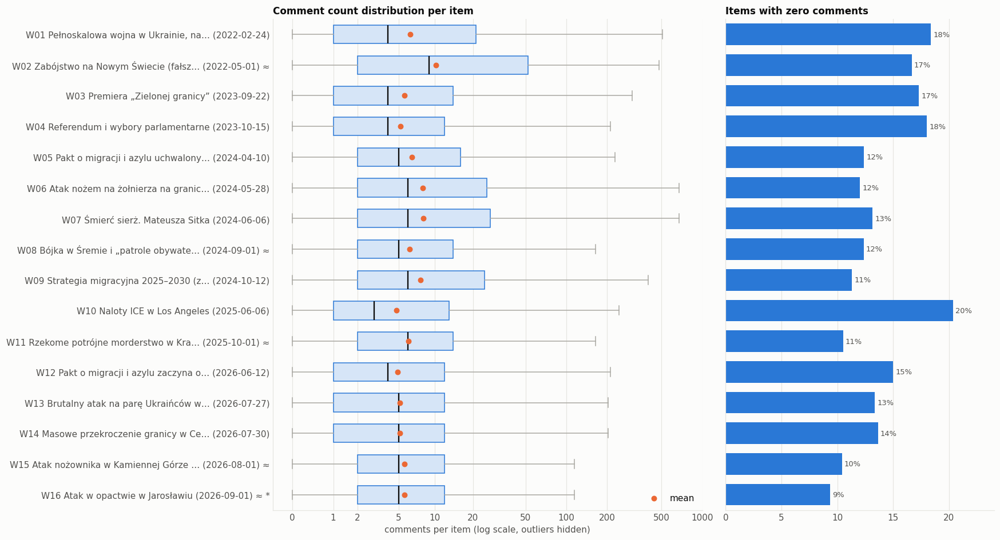

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(16, 0.45 * len(EVENTS) + 1.5), sharey=True, gridspec_kw={'width_ratios': [1.6, 1]})
data = [np.log10(1 + posts.loc[posts['event'] == e, 'comment_count'].clip(lower=0)) for e in EVENTS]
bp = axes[0].boxplot(data, **HBOX, positions=np.arange(len(EVENTS)), showfliers=False, patch_artist=True, widths=0.6,
                     medianprops=dict(color=TEXT_PRIMARY, lw=1.5), whiskerprops=dict(color=NEUTRAL),
                     capprops=dict(color=NEUTRAL), boxprops=dict(edgecolor=SERIES[0]))
for b in bp['boxes']:
    b.set_facecolor('#d6e5f7')
means = [d.mean() for d in data]
axes[0].scatter(means, range(len(EVENTS)), color=SERIES[1], s=30, zorder=3, label='mean')
axes[0].set_yticks(range(len(EVENTS)), LABELS)
axes[0].invert_yaxis() if not axes[0].yaxis_inverted() else None
ticks = [0, 1, 2, 5, 10, 20, 50, 100, 200, 500, 1000]
axes[0].set_xticks(np.log10(1 + np.array(ticks)), ticks)
axes[0].set_xlabel('comments per item (log scale, outliers hidden)')
axes[0].grid(axis='y', visible=False)
axes[0].legend(loc='lower right')
axes[0].set_title('Comment count distribution per item')

hbar(axes[1], eng['zero_comments_pct'], None, SERIES[0], fmt='{:.0f}%')
axes[1].set_title('Items with zero comments')
axes[1].tick_params(labelleft=False)
fig.tight_layout()
savefig(fig, '17_engagement')

phase,before,day_0,after
event,,,
W01,166.0,341.9,276.7
W02,377.9,273.2,241.6
W03,218.6,117.2,87.5
W04,122.4,48.0,119.6
W05,107.3,109.2,97.3
W06,99.6,238.3,230.8
W07,137.1,369.8,197.5
W08,91.2,113.9,154.9
W09,143.1,188.6,159.4


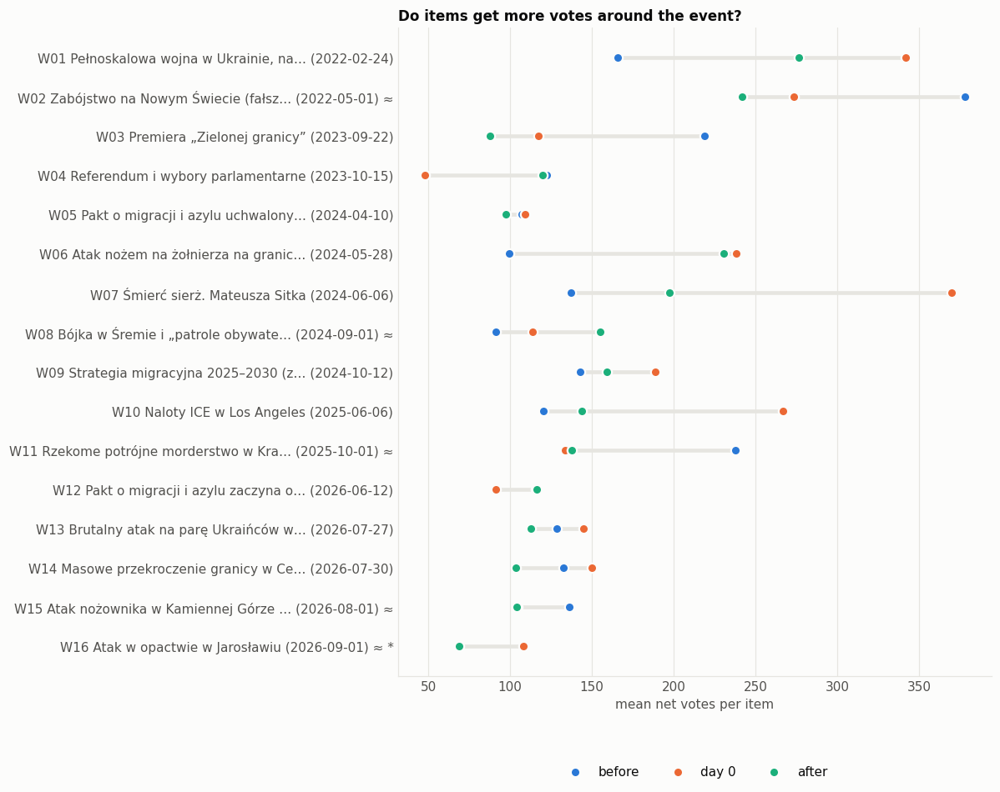

In [27]:
# Mean net votes per item by phase
ph = posts.groupby(['event', 'phase'])['votes'].mean().unstack().reindex(EVENTS).reindex(columns=['before', 'day_0', 'after'])

fig, ax = plt.subplots(figsize=(11, 0.45 * len(EVENTS) + 1.5))
y = np.arange(len(EVENTS))
ax.hlines(y, ph.min(axis=1), ph.max(axis=1), color=GRID, lw=3)
for i, c in enumerate(ph.columns):
    ax.scatter(ph[c], y, s=55, color=SERIES[i], label=c.replace('_', ' '), zorder=3, edgecolor=SURFACE, linewidth=1.5)
ax.set_yticks(y, LABELS)
ax.invert_yaxis()
ax.grid(axis='y', visible=False)
ax.set_xlabel('mean net votes per item')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=3)
ax.set_title('Do items get more votes around the event?')
fig.tight_layout()
savefig(fig, '18_votes_by_phase')
ph.round(1)

In [28]:
# Correlation between engagement metrics (Spearman, unique items)
u = posts.drop_duplicates('item_id').assign(text_len=lambda d: d['text'].str.len())
u[['votes', 'comment_count', 'collected_comments', 'text_len', 'n_keywords']].corr(method='spearman').round(2)

,votes,comment_count,collected_comments,text_len,n_keywords
votes,1.00,0.65,0.48,0.08,0.16
comment_count,0.65,1.00,0.75,0.24,0.21
collected_comments,0.48,0.75,1.00,0.14,0.09
text_len,0.08,0.24,0.14,1.00,0.44
n_keywords,0.16,0.21,0.09,0.44,1.00


## 7. Authors – how concentrated is the activity?

A handful of very active accounts can dominate keyword-based samples. Gini = 0 means every author wrote the same
amount; close to 1 means a few authors produced almost everything. Authors are hashed and never displayed.

In [29]:
def gini(x):
    x = np.sort(np.asarray(x, dtype=float))
    n = len(x)
    if n == 0 or x.sum() == 0:
        return np.nan
    return (2 * np.arange(1, n + 1) - n - 1).dot(x) / (n * x.sum())

def concentration(df):
    per_author = df.dropna(subset=['author_hash']).groupby('author_hash').size().sort_values(ascending=False)
    n = len(per_author)
    return pd.Series({
        'authors': n,
        'items_per_author': per_author.mean() if n else np.nan,
        'max_by_one_author': per_author.iloc[0] if n else 0,
        'top10_authors_%': per_author.head(10).sum() / per_author.sum() * 100 if n else np.nan,
        'top1pct_authors_%': per_author.head(max(1, n // 100)).sum() / per_author.sum() * 100 if n else np.nan,
        'single_item_authors_%': (per_author == 1).mean() * 100 if n else np.nan,
        'gini': gini(per_author.values),
    })

conc_posts = pd.DataFrame({e: concentration(posts[posts['event'] == e]) for e in EVENTS}).T
conc_comm = pd.DataFrame({e: concentration(comments[comments['event'] == e]) for e in EVENTS}).T
display(Markdown('**Items**'))
display(conc_posts.round(2))
display(Markdown('**Comments**'))
display(conc_comm.round(2))

**Items**

,authors,items_per_author,max_by_one_author,top10_authors_%,top1pct_authors_%,single_item_authors_%,gini
W01,1199.0,1.89,52.0,13.41,14.29,74.81,0.42
W02,404.0,2.92,114.0,37.68,25.66,70.54,0.59
W03,930.0,1.58,28.0,10.25,9.57,77.53,0.32
W04,982.0,1.65,23.0,11.08,10.34,75.87,0.35
W05,780.0,2.32,80.0,17.86,14.70,66.92,0.49
W06,639.0,2.10,57.0,20.91,15.91,71.05,0.46
W07,609.0,2.07,51.0,22.11,16.96,72.74,0.46
W08,835.0,2.54,114.0,23.80,20.82,69.58,0.54
W09,574.0,2.35,108.0,27.76,19.84,71.95,0.52
W10,989.0,1.76,35.0,11.06,10.37,71.99,0.37


**Comments**

,authors,items_per_author,max_by_one_author,top10_authors_%,top1pct_authors_%,single_item_authors_%,gini
W01,8090.0,3.85,107.0,2.32,11.62,45.02,0.56
W02,7141.0,4.37,140.0,3.30,12.85,42.36,0.58
W03,7145.0,4.34,183.0,3.25,12.76,43.61,0.59
W04,7224.0,4.28,172.0,3.30,13.05,43.76,0.59
W05,6623.0,4.63,383.0,5.06,14.32,42.82,0.60
W06,6714.0,4.63,298.0,4.20,13.91,42.37,0.60
W07,6777.0,4.55,260.0,4.03,13.71,42.56,0.60
W08,6836.0,4.97,227.0,4.23,14.32,41.82,0.62
W09,6499.0,4.70,155.0,3.51,12.92,42.24,0.60
W10,6927.0,4.43,161.0,3.40,12.96,42.59,0.59


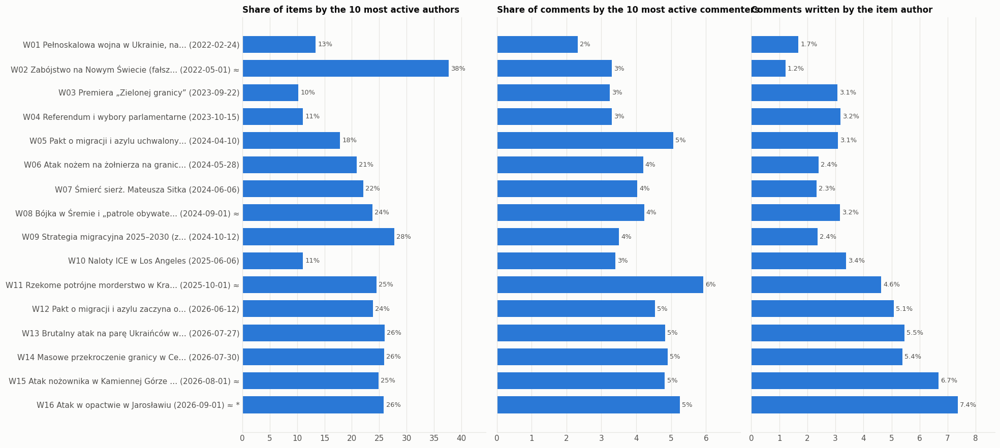

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(18, 0.42 * len(EVENTS) + 1.4), sharey=True)
hbar(axes[0], conc_posts['top10_authors_%'], LABELS, SERIES[0], fmt='{:.0f}%')
axes[0].set_title('Share of items by the 10 most active authors')
hbar(axes[1], conc_comm['top10_authors_%'], LABELS, SERIES[0], fmt='{:.0f}%')
axes[1].set_title('Share of comments by the 10 most active commenters')
self_reply = comments.groupby('event')['is_item_author'].mean().reindex(EVENTS) * 100
hbar(axes[2], self_reply, LABELS, SERIES[0], fmt='{:.1f}%')
axes[2].set_title('Comments written by the item author')
fig.tight_layout()
savefig(fig, '19_author_concentration')

## 8. Conversations

Wykop comments have two levels: top-level comments and replies to them. `latency_h` = hours between the item and the
comment (`hours_since_item_created`).

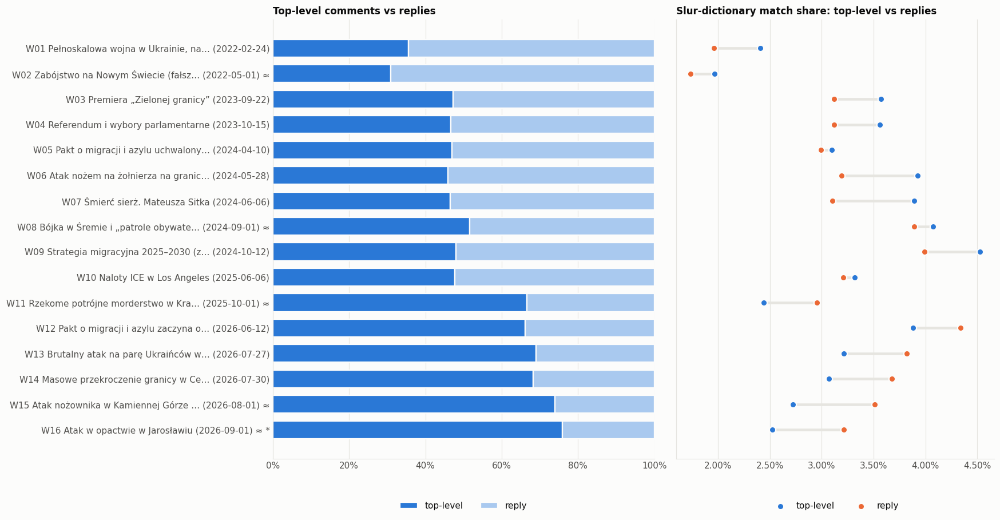

In [31]:
depth = comments.assign(level=np.where(comments['is_reply'], 'reply', 'top-level')).groupby(['event', 'level']).size().unstack(fill_value=0)
depth = depth.reindex(EVENTS).fillna(0)[['top-level', 'reply']]
depth_share = depth.div(depth.sum(axis=1).replace(0, np.nan), axis=0) * 100
slur_by_level = pl_comm.groupby(['event', 'is_reply'])['has_slur'].mean().unstack().reindex(index=EVENTS, columns=[False, True]) * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 0.42 * len(EVENTS) + 1.6), sharey=True, gridspec_kw={'width_ratios': [1.2, 1]})
left = np.zeros(len(EVENTS))
for c, col in zip(depth_share.columns, [SERIES[0], '#a9c9ef']):
    vals = depth_share[c].fillna(0).values
    axes[0].barh(range(len(EVENTS)), vals, left=left, color=col, height=0.7, edgecolor=SURFACE, linewidth=1.5, label=c)
    left += vals
axes[0].set_yticks(range(len(EVENTS)), LABELS)
axes[0].invert_yaxis() if not axes[0].yaxis_inverted() else None
axes[0].set_xlim(0, 100)
axes[0].xaxis.set_major_formatter(mticker.PercentFormatter())
axes[0].grid(axis='y', visible=False)
axes[0].legend(loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=2)
axes[0].set_title('Top-level comments vs replies')

y = np.arange(len(EVENTS))
axes[1].hlines(y, slur_by_level.min(axis=1), slur_by_level.max(axis=1), color=GRID, lw=3)
axes[1].scatter(slur_by_level[False], y, s=55, color=SERIES[0], label='top-level', zorder=3, edgecolor=SURFACE, linewidth=1.5)
axes[1].scatter(slur_by_level[True], y, s=55, color=SERIES[1], label='reply', zorder=3, edgecolor=SURFACE, linewidth=1.5)
axes[1].grid(axis='y', visible=False)
axes[1].xaxis.set_major_formatter(mticker.PercentFormatter())
axes[1].legend(loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=2)
axes[1].set_title('Slur-dictionary match share: top-level vs replies')
fig.tight_layout()
savefig(fig, '20_replies')

,median_h,p75_h,p90_h,within_1h_pct,within_24h_pct
event,,,,,
W01,3.60,10.19,18.69,21.11,96.70
W02,5.52,13.74,21.75,10.88,93.97
W03,5.83,14.94,23.16,15.12,91.61
W04,5.85,15.76,23.20,15.12,91.37
W05,7.27,16.61,24.14,13.86,89.68
W06,7.31,16.20,23.77,11.93,90.53
W07,6.84,15.60,23.37,11.96,91.18
W08,7.41,16.10,23.75,14.54,90.52
W09,8.43,16.94,24.28,11.78,89.50


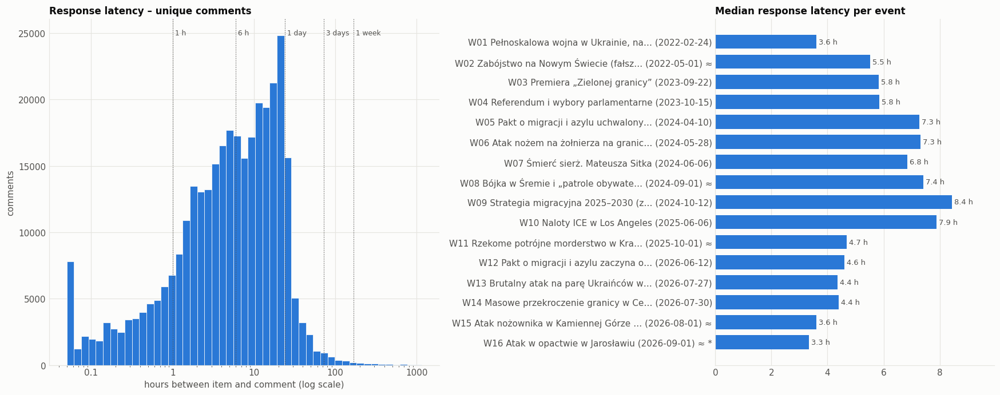

In [32]:
lat = comments.groupby('event')['latency_h'].agg(
    median_h='median',
    p75_h=lambda s: s.quantile(0.75),
    p90_h=lambda s: s.quantile(0.9),
    within_1h_pct=lambda s: (s <= 1).mean() * 100,
    within_24h_pct=lambda s: (s <= 24).mean() * 100,
).reindex(EVENTS)

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8 + 0.1 * len(EVENTS)), gridspec_kw={'width_ratios': [1.4, 1]})
lat_all = comments.drop_duplicates('comment_id')['latency_h'].clip(lower=0.05)
bins = np.logspace(np.log10(0.05), np.log10(max(lat_all.max(), 200)), 50)
axes[0].hist(lat_all, bins=bins, color=SERIES[0], edgecolor=SURFACE, linewidth=0.5)
axes[0].set_xscale('log')
for v, name in [(1, '1 h'), (6, '6 h'), (24, '1 day'), (72, '3 days'), (168, '1 week')]:
    axes[0].axvline(v, color=TEXT_SECONDARY, lw=0.8, ls=':')
    axes[0].text(v, axes[0].get_ylim()[1] * 0.97, f' {name}', fontsize=8, color=TEXT_SECONDARY, va='top')
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:g}'))
axes[0].set_xlabel('hours between item and comment (log scale)')
axes[0].set_ylabel('comments')
axes[0].set_title('Response latency – unique comments')

hbar(axes[1], lat['median_h'], LABELS, SERIES[0], fmt='{:.1f} h')
axes[1].set_title('Median response latency per event')
fig.tight_layout()
savefig(fig, '21_latency')
lat.round(2)

In [33]:
# Comments per thread & coverage: comments collected in the window vs comment_count reported by Wykop
thr = posts[posts['collected_comments'] > 0].groupby('event')['collected_comments'].describe(
    percentiles=[0.5, 0.9, 0.99])[['count', 'mean', '50%', '90%', '99%', 'max']]
thr.columns = ['threads_w_comments', 'mean', 'median', 'p90', 'p99', 'max']
cov = posts.groupby('event')[['comment_count', 'collected_comments']].sum()
cov['collected_vs_reported_%'] = cov['collected_comments'] / cov['comment_count'].replace(0, np.nan) * 100
thr.reindex(EVENTS).join(cov).round(1)

,threads_w_comments,mean,median,p90,p99,max,comment_count,collected_comments,collected_vs_reported_%
event,,,,,,,,,
W01,739.0,42.2,9.0,126.0,308.2,375.0,65266,31158,47.7
W02,673.0,46.4,24.0,111.0,362.0,479.0,45334,31208,68.8
W03,1058.0,29.3,6.0,95.6,285.2,475.0,38209,30994,81.1
W04,1186.0,26.0,5.0,84.0,238.3,475.0,36686,30894,84.2
W05,1256.0,24.4,7.0,75.5,209.9,408.0,39755,30639,77.1
W06,978.0,31.8,8.0,91.0,230.2,1084.0,39908,31096,77.9
W07,963.0,32.0,8.0,93.6,225.8,1084.0,39747,30845,77.6
W08,1465.0,23.2,7.0,74.6,189.1,299.0,41919,34006,81.1
W09,1096.0,27.8,7.0,86.0,211.1,378.0,35812,30521,85.2


In [34]:
# Most discussed items (titles / opening text only – no IDs, links or authors)
most = posts.sort_values('collected_comments', ascending=False).drop_duplicates('item_id').head(15)
most.assign(text=most['text'].map(short), keywords=most['matched_keywords'].map(lambda L: ', '.join(kw_label(k) for k in L[:4])))[
    ['event', 'item_type', 'relative_day', 'collected_comments', 'comment_count', 'votes', 'keywords', 'text']
].reset_index(drop=True)

,event,item_type,relative_day,collected_comments,comment_count,votes,keywords,text
0,W06,link,8,1084,1135,7636,"uchodźcy, Polska, POL: granica","Polscy żołnierze zakuci w kajdanki na białoruskiej granicy. W wojsku wrze Żandarmeria Wojskowa zatrzymała trzech żołnierzy, którzy oddal..."
1,W11,link,-18,747,768,2762,"Ukraina, wojna, Rosja, Polska","Paweł Svinarski z kanału ""dla pieniędzy"" szerzy rosyjską dezinformację Paweł Svinarski prowadzący kanał YouTube z 1.24 mln subskrybentów..."
2,W16,link,23,635,654,2557,"Ukraina, Polska, UA: ukraina, UA: ukrainiec_ukrainka","Atak w klasztorze. Pięć osób rannych, wśród nich księża Policja potwierdziła Interii, że doszło do ataku na terenie klasztoru w Jarosław..."
3,W07,link,1,603,672,5175,"migranci, imigranci, Polska, POL: granica","Mateusz Sitek. Żołnierz zamordowany przez migranta na granicy Żołnierz, który został zamordowany przez agresywnego migranta na granicy p..."
4,W02,link,14,479,482,1500,"Ukraina, wojna, Polska, UA: ukraina","Ukraińcy są wściekli na własne jury, setki komentarzy przepraszające Polaków. Takich komentarzy są setki. Pomóżcie proszę wykopać żeby c..."
5,W03,link,1,475,497,1016,"Polska, POL: granica",Ocena 2.2 / 10 Zielona granica Holland nie spodobała się społeczeństwu Bankructwo Holland i środowisk atakujących polską państwowość i r...
6,W10,link,-2,468,464,2817,"Ukraina, wojna, Rosja, UA: ukraina","Cały film z ukraińskiej operacji ""Pajęczyna"" Na nagraniu trafiono 27 samolotów."
7,W04,link,-22,461,464,1032,"imigranci, Polska, POL: granica",Niemcy zmieniają zdanie. MSW chce stałych kontroli na granicy z Polską Szefowa MSW Niemiec Nancy Faeser długo odmawiała wprowadzenia sta...
8,W10,link,-13,449,540,5966,"Polska, REF: azyl_deportacja",Policja: Sebastian Majtczak zatrzymany! Teraz deportacja do Polski! Wczoraj na terenie Zjednoczonych Emiratów Arabskich zatrzymany zosta...
9,W03,link,17,448,471,367,"Polska, POL: wybory",Wybory i referendum. Czy można nie pobierać wszystkich kart? W momencie wręczania członkowi komisji wyborczej dowodu tożsamości powinniś...


## 9. When people comment

Unique comments by weekday and hour (Europe/Warsaw); the right panel shows the slur-dictionary match share among Polish
comments (cells with < `MIN_DAY_N` comments left blank).

Busiest slot: **Sun 12:00** (3,493 comments); match share ranges 1.6–6.7% across slots.

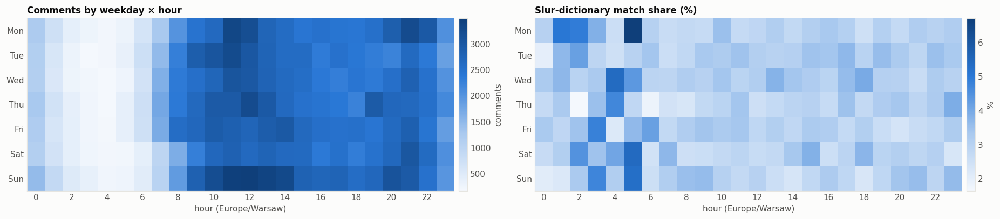

In [35]:
uc = comments.drop_duplicates('comment_id')
uc = uc.assign(weekday=uc['created_local'].dt.weekday, hour=uc['created_local'].dt.hour)
WD = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
vol = uc.pivot_table(index='weekday', columns='hour', values='comment_id', aggfunc='size').reindex(index=range(7), columns=range(24)).fillna(0)
upl = uc[uc['is_pl']]
n_pl = upl.pivot_table(index='weekday', columns='hour', values='has_slur', aggfunc='size').reindex(index=range(7), columns=range(24))
shr = upl.pivot_table(index='weekday', columns='hour', values='has_slur', aggfunc='mean').reindex(index=range(7), columns=range(24))
shr = shr.where(n_pl >= MIN_DAY_N) * 100

fig, axes = plt.subplots(1, 2, figsize=(17, 3.8))
for ax, M, title, lab in [(axes[0], vol, 'Comments by weekday × hour', 'comments'),
                          (axes[1], shr, 'Slur-dictionary match share (%)', '%')]:
    im = ax.imshow(M.values, aspect='auto', cmap=SEQ)
    ax.set_yticks(range(7), WD)
    ax.set_xticks(range(0, 24, 2), range(0, 24, 2))
    ax.grid(False)
    ax.set_xlabel('hour (Europe/Warsaw)')
    ax.set_title(title)
    fig.colorbar(im, ax=ax, fraction=0.03, pad=0.01).set_label(lab)
fig.tight_layout()
savefig(fig, '22_weekday_hour')
pk = vol.stack().idxmax()
display(Markdown(f"Busiest slot: **{WD[pk[0]]} {pk[1]}:00** ({int(vol.loc[pk]):,} comments); match share ranges "
                 f"{np.nanmin(shr.values):.1f}–{np.nanmax(shr.values):.1f}% across slots."))

## 10. Text

### 10.1 Comment length and Wykop tags

**Top 10 Wykop tags of items**

,1,2,3,4,5,6,7,8,9,10
"W01 Pełnoskalowa wojna w Ukrainie, na… (2022-02-24)",ukraina (1800),wojna (1407),rosja (1035),polska (804),europa (567),swiat (332),polityka (255),uchodzcy (218),geopolityka (158),wojsko (97)
W02 Zabójstwo na Nowym Świecie (fałsz… (2022-05-01) ≈,ukraina (1053),wojna (915),rosja (813),europa (497),swiat (383),polska (247),ruskimir (182),polityka (172),wydarzenia (103),wojsko (92)
W03 Premiera „Zielonej granicy” (2023-09-22),wybory (544),polityka (438),ukraina (309),polska (298),wojna (251),referendum (176),rosja (172),bekazpisu (166),imigranci (111),bekazlewactwa (98)
W04 Referendum i wybory parlamentarne (2023-10-15),wybory (551),polityka (467),ukraina (353),polska (297),wojna (293),rosja (207),referendum (179),bekazpisu (170),imigranci (147),bekazlewactwa (106)
W05 Pakt o migracji i azylu uchwalony… (2024-04-10),ukraina (1254),wojna (932),rosja (901),polityka (350),polska (289),wojsko (124),imigranci (101),europa (90),usa (86),ciekawostki (72)
W06 Atak nożem na żołnierza na granic… (2024-05-28),ukraina (749),wojna (573),rosja (471),polityka (308),polska (279),imigranci (240),wojsko (127),bekazlewactwa (89),bialorus (75),4konserwy (70)
W07 Śmierć sierż. Mateusza Sitka (2024-06-06),ukraina (665),wojna (526),rosja (427),polityka (322),polska (270),imigranci (261),wojsko (121),bekazlewactwa (98),bialorus (81),granica (76)
W08 Bójka w Śremie i „patrole obywate… (2024-09-01) ≈,ukraina (1452),wojna (902),rosja (872),polityka (436),imigranci (307),polska (290),bekazlewactwa (183),europa (127),niemcy (102),wojsko (96)
W09 Strategia migracyjna 2025–2030 (z… (2024-10-12),ukraina (703),wojna (465),polityka (405),rosja (394),imigranci (292),polska (263),bekazlewactwa (181),europa (128),niemcy (95),usa (80)
W10 Naloty ICE w Los Angeles (2025-06-06),polityka (594),ukraina (455),wojna (380),rosja (360),imigranci (310),polska (279),wybory (160),usa (112),bekazpisu (96),heheszki (84)


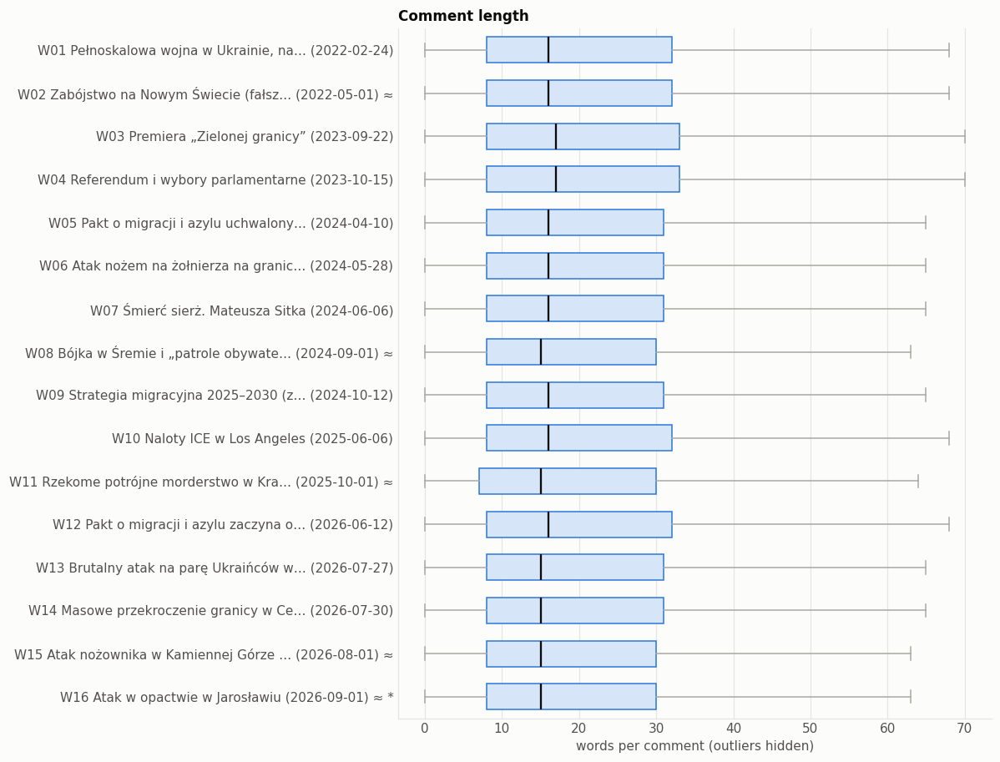

In [36]:
WORD_RE = re.compile(r'[^\W\d_]+')
uc_words = comments_all.set_index('comment_id')['body'].map(lambda t: len(WORD_RE.findall(USER_RE.sub(' ', LINK_RE.sub(' ', t)))))
comments['n_words'] = comments['comment_id'].map(uc_words)

fig, ax = plt.subplots(figsize=(11, 0.45 * len(EVENTS) + 1.2))
data = [comments.loc[comments['event'] == e, 'n_words'] for e in EVENTS]
bp = ax.boxplot(data, **HBOX, showfliers=False, patch_artist=True, widths=0.6,
                medianprops=dict(color=TEXT_PRIMARY, lw=1.5), whiskerprops=dict(color=NEUTRAL),
                capprops=dict(color=NEUTRAL), boxprops=dict(edgecolor=SERIES[0]))
for b in bp['boxes']:
    b.set_facecolor('#d6e5f7')
ax.set_yticks(range(1, len(EVENTS) + 1), LABELS)
ax.invert_yaxis()
ax.grid(axis='y', visible=False)
ax.set_xlabel('words per comment (outliers hidden)')
ax.set_title('Comment length')
fig.tight_layout()
savefig(fig, '23_comment_length')

def top_items(series_of_lists, n):
    c = Counter(x for lst in series_of_lists for x in lst)
    return [f'{w} ({k})' for w, k in c.most_common(n)]

tags_table = pd.DataFrame({LABEL[e]: pd.Series(top_items(posts.loc[posts['event'] == e, 'tags'], 10)) for e in EVENTS}).T
tags_table.columns = range(1, tags_table.shape[1] + 1)
display(Markdown('**Top 10 Wykop tags of items**'))
tags_table.fillna('')

### 10.2 Most frequent words in comments

In [37]:
STOPWORDS = set("""
a aby ach acz aczkolwiek aj albo ale alez ależ ani az aż bardziej bardzo beda bedzie będą będzie bez bo bowiem by byc być byl byla byli bylo byly był była było były bym bys byś caly cała cały ci cie cię ciebie co cos coś czy czyli daleko dla dlaczego dlatego do dobrze dokad dokąd dosc dość duzo dużo dwa dwaj dwie dwoje dzis dziś dzisiaj gdy gdyby gdyz gdyż gdzie gdzies gdzieś go i ich ile im inna inne inny innych iz iż ja jak jakas jakaś jakby jaki jakichs jakie jakis jakiś jakiz jakos jakoś jako ją je jeden jedna jednak jednakze jedno jego jej jemu jesli jeśli jest jestem jeszcze jezeli jeżeli juz już kazdy każdy kiedy kilka kims kimś kto ktora która ktore które ktorego którego ktorej której ktory który ktorych których ktorym którym ktorzy którzy ktos ktoś ku lat lecz lub ma maja mają mam mi miedzy między mimo mna mną mnie moga mogą moi moim moj mój moja moje moze może mozliwe mozna można mu musi my na nad nam nami nas nasi nasz nasza nasze naszego naszych natomiast natychmiast nawet nia nią nic nich nie niech niego niej niemu nigdy nim nimi niz niż no o obok od około ok on ona one oni ono oraz oto owszem pan pana pani po pod podczas pomimo ponad poniewaz ponieważ powinien powinna powinni powinno poza prawie przeciez przecież przed przede przedtem przez przy roku rowniez również sa są sam sama sie się skad skąd soba sobą sobie sposob sposób swoje ta tak taka taki takie takze także tam te tego tej temu ten teraz tez też to toba tobą tobie totez toteż trzeba tu tutaj twoi twoim twoj twój twoja twoje twym ty tych tylko tym tys tzw u w wam wami was wasz wasza wasze we według wiele wielu wiec więc wiecej więcej wlasnie właśnie wszyscy wszystkich wszystkie wszystkim wszystko wtedy wy z za zaden żaden zadna żadna zadne żadne zadnych żadnych zapewne zawsze ze zeby żeby zl znow znów znowu zostal został że jakiej jakim jakich jaką tą tę były będę byłem chyba naprawdę właściwie tyle siebie mieć nikt xd xdd http https www com user link oryginał zmniejszony spoiler pokaż kurwa
the and for that this with you are was not but have has from they all just what about like will can out more one their there
""".split())
TOKEN_RE = re.compile(r'[^\W\d_]{3,}')

def tokens(text):
    text = USER_RE.sub(' ', LINK_RE.sub(' ', text.lower()))
    return [w for w in TOKEN_RE.findall(text) if w not in STOPWORDS]

TOKENS = comments_all.set_index('comment_id')['body'].map(tokens)   # each comment tokenised once
comments['tokens'] = comments['comment_id'].map(TOKENS)
TOP_WORDS = 15
cw = pd.DataFrame({LABEL[e]: pd.Series(top_items(comments.loc[(comments['event'] == e) & comments['is_pl'], 'tokens'], TOP_WORDS))
                   for e in EVENTS}).T
cw.columns = range(1, cw.shape[1] + 1)
display(Markdown(f'**Top {TOP_WORDS} words in Polish comments (stop-words removed)**'))
cw.fillna('')

**Top 15 words in Polish comments (stop-words removed)**

,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
"W01 Pełnoskalowa wojna w Ukrainie, na… (2022-02-24)",ludzi (1186),rosji (1173),ukrainy (1150),rosja (1125),ludzie (1063),wojny (987),nato (985),ukraina (970),polsce (969),putin (955),kraju (898),polski (871),usa (851),polska (851),masz (791)
W02 Zabójstwo na Nowym Świecie (fałsz… (2022-05-01) ≈,ukraina (1598),ukrainy (1284),rosji (1116),rosja (1102),ukrainie (1087),ukraińcy (1050),wojny (1020),ludzi (932),polsce (868),masz (866),wiem (828),wojna (824),pewnie (806),polski (796),polska (768)
W03 Premiera „Zielonej granicy” (2023-09-22),pis (2364),referendum (2280),film (1417),polski (1191),ludzie (1185),ludzi (1179),polsce (1144),polska (1025),kraju (948),masz (915),ukraina (899),chce (790),granicy (784),samo (755),ukrainy (733)
W04 Referendum i wybory parlamentarne (2023-10-15),referendum (2530),pis (2243),ludzie (1165),ludzi (1159),film (1157),polski (1120),polsce (1074),polska (966),masz (923),ukraina (915),kraju (869),chce (783),samo (775),pytania (754),niemcy (739)
W05 Pakt o migracji i azylu uchwalony… (2024-04-10),polsce (1121),rosja (1096),ukraina (1060),wojny (1050),ludzi (1044),ukrainy (1031),usa (1009),rosji (952),polski (934),ludzie (918),kraju (901),masz (889),ukraińcy (850),ukrainie (823),polska (800)
W06 Atak nożem na żołnierza na granic… (2024-05-28),ludzi (1163),polski (1068),polsce (1027),kraju (1022),granicy (1011),ludzie (960),wojny (920),ukraina (832),masz (810),rosja (795),pewnie (788),ukrainy (784),rosji (776),ukraińcy (746),polska (746)
W07 Śmierć sierż. Mateusza Sitka (2024-06-06),ludzi (1148),granicy (1087),polski (1034),kraju (1002),polsce (984),ludzie (948),wojny (912),masz (815),ukrainy (805),ukraina (795),rosji (772),pewnie (746),rosja (736),polska (716),wiem (701)
W08 Bójka w Śremie i „patrole obywate… (2024-09-01) ≈,polsce (1123),ludzi (1112),ukraina (1095),polski (1076),kraju (1018),ludzie (964),ukrainy (948),rosja (923),wojny (901),polska (863),usa (837),masz (829),rosji (801),ukraińcy (801),samo (774)
W09 Strategia migracyjna 2025–2030 (z… (2024-10-12),polsce (1115),polski (1047),ludzi (1022),kraju (958),ludzie (898),ukraina (894),polska (823),ukrainy (808),masz (762),usa (758),wojny (750),samo (706),wiem (675),pewnie (656),ukraińcy (653)
W10 Naloty ICE w Los Angeles (2025-06-06),pis (1540),polski (1266),polsce (1172),ludzi (1083),ludzie (1015),kraju (959),masz (925),imigrantów (893),polska (863),samo (751),niemcy (749),usa (735),pracy (717),mamy (706),wiem (700)


### 10.3 Words that rise after the event

For each event: words whose relative frequency in Polish comments grew most from the *before* phase to the event period
and *after* phase (smoothed log-ratio; the word must appear ≥ `MIN_AFTER` times after). This often surfaces
event-specific vocabulary (places, names) that the dictionaries do not capture.

In [38]:
MIN_AFTER, TOP_RISING = 15, 12

def rising_words(e):
    c = comments[(comments['event'] == e) & comments['is_pl'] & (comments['relative_day'] <= LAST_DAY[e])]
    before = Counter(w for t in c.loc[c['phase'] == 'before', 'tokens'] for w in t)
    after = Counter(w for t in c.loc[c['phase'] != 'before', 'tokens'] for w in t)
    nb, na = sum(before.values()), sum(after.values())
    if nb == 0 or na == 0:
        return []
    vocab = len(set(before) | set(after))
    scores = {w: np.log((after[w] + 1) / (na + vocab)) - np.log((before[w] + 1) / (nb + vocab))
              for w in after if after[w] >= MIN_AFTER}
    best = sorted(scores, key=scores.get, reverse=True)[:TOP_RISING]
    return [f'{w} ({before[w]}→{after[w]})' for w in best]

rising = pd.DataFrame({LABEL[e]: pd.Series(rising_words(e)) for e in EVENTS}).T
rising.columns = range(1, rising.shape[1] + 1)
rising.fillna('')

,1,2,3,4,5,6,7,8,9,10,11,12
"W01 Pełnoskalowa wojna w Ukrainie, na… (2022-02-24)",abonament (0→42),ciapatych (0→35),braun (0→29),dyskryminacja (0→29),hotel (0→29),sali (0→28),przemyślu (0→28),nwo (0→27),uchodźcom (3→110),kolejki (0→25),dokumentów (2→76),dofinansowanie (0→24)
W02 Zabójstwo na Nowym Świecie (fałsz… (2022-05-01) ≈,jury (0→101),konkurs (0→69),benefity (1→132),narodowości (0→54),wisła (0→40),kissinger (0→38),eurowizja (0→35),katolik (0→32),salon (0→31),pretensje (0→29),kot (0→29),siewierodonieck (0→29)
W03 Premiera „Zielonej granicy” (2023-09-22),frekwencji (0→159),wiążące (0→147),referendalnej (0→66),hamas (0→61),wyprzedaż (0→57),referendum (39→2241),frekwencję (0→49),frekwencja (2→138),kukiz (0→45),ciszy (0→41),referendalną (0→35),aborygeni (0→35)
W04 Referendum i wybory parlamentarne (2023-10-15),aborygeni (0→35),sct (0→20),invitro (0→18),szmaty (0→16),serbia (1→32),hotelu (0→15),pijanych (1→27),fico (1→26),rubli (1→24),kontenery (1→22),alkoholu (1→20),jazdy (3→37)
W05 Pakt o migracji i azylu uchwalony… (2024-04-10),ooooo (0→30),helikopter (0→27),dzietność (1→52),migracyjny (0→23),multikulti (0→17),witaminki (0→15),ciapatych (0→15),europosłowie (0→15),aborcja (1→25),morale (1→24),emocje (1→21),paktu (1→20)
W06 Atak nożem na żołnierza na granic… (2024-05-28),batorego (0→51),soros (0→47),sorosa (0→44),prokuratora (0→38),strzały (1→57),stealth (0→27),ranny (0→24),strzelanie (1→47),koniecznej (0→20),janeczek (0→20),kurdej (1→40),ostrzegawcze (1→39)
W07 Śmierć sierż. Mateusza Sitka (2024-06-06),batorego (0→57),sorosa (0→55),soros (0→54),przystanku (0→28),stealth (0→27),bosak (0→22),janeczek (0→20),prokuratora (1→37),janukowycz (0→17),palestuchy (0→17),fundacje (0→16),combat (0→16)
W08 Bójka w Śremie i „patrole obywate… (2024-09-01) ≈,policji (0→125),azylu (0→123),uchodźcy (0→117),wiz (0→101),pracowników (0→90),migracji (0→87),rasizm (0→85),imigracja (0→70),przestępstw (0→69),przestępców (0→68),kary (0→63),dziecka (0→62)
W09 Strategia migracyjna 2025–2030 (z… (2024-10-12),spacex (0→27),unrwa (0→24),centrów (0→24),ciele (0→23),cpk (0→22),białorusin (0→21),zawiesić (0→17),duchami (0→16),dysforii (0→15),zarabiamy (1→31),czarnoskórych (1→29),cement (2→37)
W10 Naloty ICE w Los Angeles (2025-06-06),iran (1→140),słupska (0→25),iranie (0→19),szwaby (0→18),zbiórki (0→17),azylanci (0→16),nauczyciel (0→15),kalifornia (0→15),płaczek (0→15),iranu (3→51),przedsiębiorca (1→24),stycznia (1→20)


## 11. Comment text quality

Language comes from the collector (`lang`, lingua detector; `und` = confidence too low). Every comment gets one
`quality` label (checked in this order):

| label | rule |
|---|---|
| `no_text` | empty, or only links / mentions / numbers / punctuation |
| `emoji_only` | nothing but emoji (plus optional links / mentions / punctuation) |
| `very_short` | fewer than `MIN_WORDS` words once links and mentions are removed |
| `other_language` | detected language is not Polish |
| `unclear_language` | language could not be determined (`und`) |
| `polish` | Polish text with at least `MIN_WORDS` words, the **clean** comments |

Nothing is removed here: the labels are flags, and `comments_clean` is the filtered view.

In [39]:
MIN_WORDS = 3
CLEAN_LABELS = {'polish'}       # add 'very_short' to keep short Polish replies
EMOJI_RE = re.compile('[\U0001F000-\U0001FAFF☀-➿⬀-⯿←-⇿️‍⃣]')
QUALITY_ORDER = ['polish', 'very_short', 'emoji_only', 'no_text', 'other_language', 'unclear_language']

def text_quality(text, lang):
    rest = USER_RE.sub(' ', LINK_RE.sub(' ', text))
    words = WORD_RE.findall(rest)
    if not words:
        return 'emoji_only' if EMOJI_RE.search(text) else 'no_text'
    if len(words) < MIN_WORDS:
        return 'very_short'
    if lang == 'pl':
        return 'polish'
    return 'unclear_language' if lang in ('und', None) or pd.isna(lang) else 'other_language'

QUALITY = pd.Series([text_quality(t, l) for t, l in zip(comments_all['body'], comments_all['lang'])], index=comments_all['comment_id'])
comments['quality'] = pd.Categorical(comments['comment_id'].map(QUALITY), categories=QUALITY_ORDER)
comments['is_clean'] = comments['quality'].isin(CLEAN_LABELS)
comments_clean = comments[comments['is_clean']].copy()

uq = comments.drop_duplicates('comment_id')
overall_q = uq['quality'].value_counts().reindex(QUALITY_ORDER).to_frame('comments')
overall_q['share_%'] = (overall_q['comments'] / len(uq) * 100).round(2)
display(Markdown(f"**{uq['is_clean'].sum():,} of {len(uq):,} unique comments ({uq['is_clean'].mean() * 100:.1f}%) are clean** "
                 f"(labels: {', '.join(sorted(CLEAN_LABELS))})"))
overall_q

**309,539 of 330,290 unique comments (93.7%) are clean** (labels: polish)

,comments,share_%
quality,,
polish,309539,93.72
very_short,12497,3.78
emoji_only,46,0.01
no_text,3561,1.08
other_language,1038,0.31
unclear_language,3609,1.09


,comments,clean,clean_%,clean_commenters,polish,very_short,emoji_only,no_text,other_language,unclear_language
event,,,,,,,,,,
W01,31158,29292,94.0,7753,29292,1095,0,258,134,379
W02,31208,29235,93.7,6858,29235,1167,0,302,113,391
W03,30994,29169,94.1,6851,29169,1142,2,274,79,328
W04,30894,29071,94.1,6920,29071,1126,2,285,79,331
W05,30639,28735,93.8,6343,28735,1173,4,289,92,346
W06,31096,29291,94.2,6481,29291,1129,6,279,79,312
W07,30845,29063,94.2,6547,29063,1116,5,269,82,310
W08,34006,31922,93.9,6571,31922,1268,6,344,123,343
W09,30521,28747,94.2,6268,28747,1093,6,267,104,304


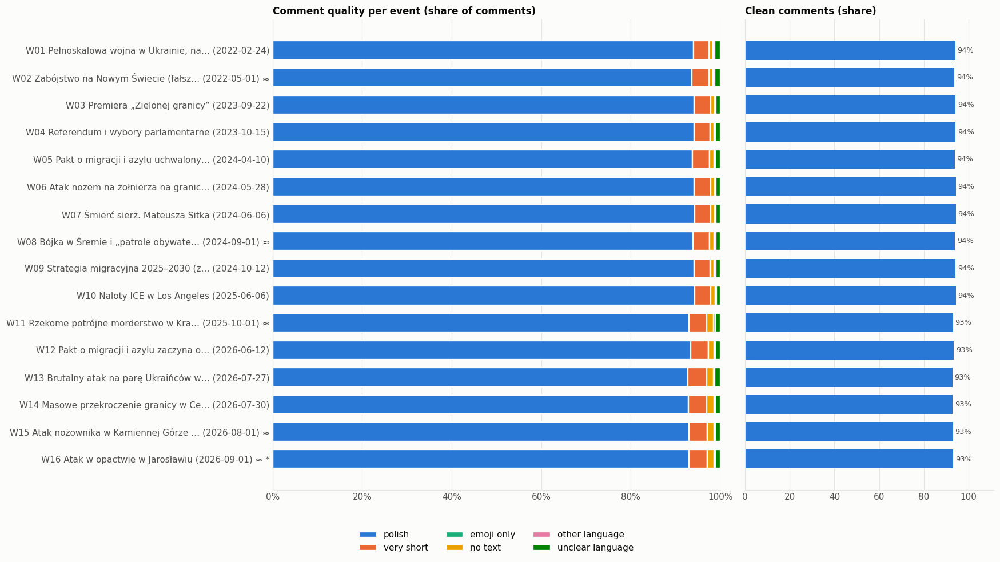

In [40]:
# Quality mix per event + how many comments remain after cleaning
qmix = (comments.groupby(['event', 'quality'], observed=False).size().unstack(fill_value=0)
        .reindex(index=EVENTS, columns=QUALITY_ORDER, fill_value=0))
qshare = qmix.div(qmix.sum(axis=1).replace(0, np.nan), axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 0.45 * len(EVENTS) + 1.8), sharey=True, gridspec_kw={'width_ratios': [1.8, 1]})
left = np.zeros(len(EVENTS))
y = np.arange(len(EVENTS))
for i, c in enumerate(QUALITY_ORDER):
    vals = qshare[c].fillna(0).values
    axes[0].barh(y, vals, left=left, color=SERIES[i], height=0.7, edgecolor=SURFACE, linewidth=1.5, label=c.replace('_', ' '))
    left += vals
axes[0].set_yticks(y, LABELS)
axes[0].invert_yaxis() if not axes[0].yaxis_inverted() else None
axes[0].set_xlim(0, 100)
axes[0].xaxis.set_major_formatter(mticker.PercentFormatter())
axes[0].grid(axis='y', visible=False)
axes[0].legend(loc='upper center', bbox_to_anchor=(0.5, -0.07), ncol=3)
axes[0].set_title('Comment quality per event (share of comments)')

hbar(axes[1], qshare[[c for c in QUALITY_ORDER if c in CLEAN_LABELS]].sum(axis=1), None, SERIES[0], fmt='{:.0f}%')
axes[1].set_title('Clean comments (share)')
axes[1].tick_params(labelleft=False)
fig.tight_layout()
savefig(fig, '24_comment_quality')

clean_summary = pd.DataFrame({
    'comments': qmix.sum(axis=1),
    'clean': comments_clean.groupby('event').size().reindex(EVENTS, fill_value=0),
})
clean_summary['clean_%'] = (clean_summary['clean'] / clean_summary['comments'].replace(0, np.nan) * 100).round(1)
clean_summary['clean_commenters'] = comments_clean.groupby('event')['author_hash'].nunique().reindex(EVENTS)
clean_summary.join(qmix)

### 11.1 Language confidence

Distribution of the detector's confidence for comments labelled Polish vs the rest – low-confidence Polish comments
are mostly short replies.

quality,polish,very_short,emoji_only,no_text,other_language,unclear_language,All
lang,,,,,,,
other,0,895,0,3,1038,0,1936
pl,309539,7814,0,4,0,0,317357
und,0,3788,46,3554,0,3609,10997
All,309539,12497,46,3561,1038,3609,330290


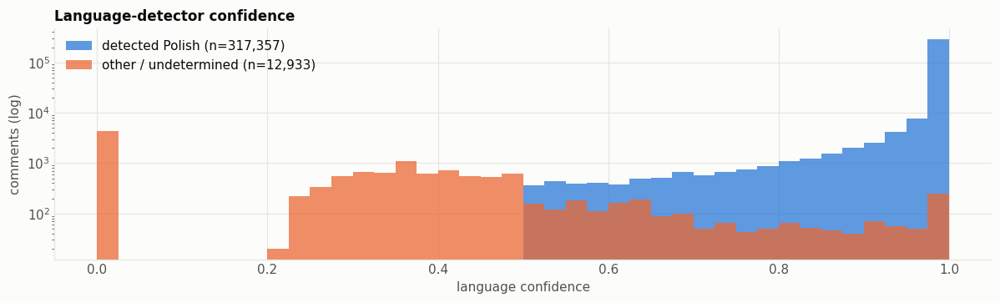

In [41]:
fig, ax = plt.subplots(figsize=(11, 3.4))
bins = np.linspace(0, 1, 41)
for lab, m, col in [('detected Polish', uq['is_pl'], SERIES[0]), ('other / undetermined', ~uq['is_pl'], SERIES[1])]:
    ax.hist(uq.loc[m, 'lang_confidence'].dropna(), bins=bins, color=col, alpha=0.75, label=f'{lab} (n={m.sum():,})')
ax.set_yscale('log')
ax.set_xlabel('language confidence')
ax.set_ylabel('comments (log)')
ax.legend(loc='upper left')
ax.set_title('Language-detector confidence')
fig.tight_layout()
savefig(fig, '25_lang_confidence')
pd.crosstab(uq['lang'].where(uq['lang'].isin(['pl', 'und']), 'other'), uq['quality'], margins=True)

### 11.2 Examples per label

Random fragments for checking the labels by hand (links shown as `[link]`, mentions removed, max 180 characters).
Change `EXAMPLE_SEED` to see others.

In [42]:
EXAMPLE_SEED, N_EXAMPLES = 0, 6
examples = pd.concat([g.sample(min(N_EXAMPLES, len(g)), random_state=EXAMPLE_SEED)
                      for _, g in uq.groupby('quality', observed=True)])
examples.assign(text=examples['body'].map(short))[['quality', 'lang', 'n_words', 'event', 'text']].reset_index(drop=True)

,quality,lang,n_words,event,text
0,polish,pl,41,W05,Dobrze by bylo jakby Ukraina zaczela zabeirac majatki oligarchom i dawac kawalki ziemii i ten majatek dla broniacych kraju zolnierzy. Je...
1,polish,pl,44,W12,"ja jednak sądzę, że to dlatego ze wychowałeś się w narodzie morderców, pęd i nekrofilow. Swoją drogą bawi, jak udajesz że ukry nie zrobi..."
2,polish,pl,13,W11,miło że mnie śledzisz. Zacząłeś pisać o bezpośrednich przyczynach. Do tego się odnieś
3,polish,pl,21,W04,Koledzy widzę nie rozpoznają ironii. (I takich nam trzeba na tagu.) Nie mniej szanuję za zdrowy odruch obywatelski i trzeźwe myślenie.
4,polish,pl,41,W08,i po to sciagaja miliony migrantow aby obrzydzic socjalizm dla ciemnej masy. w nowym wspanialym swiecie socjalizm ma byc tylko dla korpo...
5,polish,pl,5,W02,Szkoda że Liveleaka usuneli :C
6,very_short,pl,2,W06,w sumie…
7,very_short,und,1,W12,Tak.
8,very_short,pl,2,W08,"chciałbyś, klaunie."
9,very_short,pl,1,W01,zobaczymy


In [43]:
# Repeated texts among clean comments within an event (copy-paste, spam). Checked per event: windows overlap,
# so the same comment legitimately appears under several events.
dup_key = comments_clean.assign(norm=comments_clean['body'].str.strip().str.lower())
is_dup = dup_key.duplicated(['event', 'norm'])
repeated = dup_key.groupby(['event', 'norm']).size().loc[lambda s: s > 1].sort_values(ascending=False)
cross_event = comments.duplicated('comment_id').sum()
display(Markdown(f"**{is_dup.sum():,}** clean comment rows ({is_dup.mean() * 100:.1f}%) repeat a text already seen in the same "
                 f"event; {len(repeated):,} distinct texts occur more than once. Separately, **{cross_event:,}** comment rows "
                 f"are the same comment counted for more than one (overlapping) event. Bot comments excluded: "
                 f"**{int(comments_all['is_bot'].sum()):,}**."))
repeated.head(15).rename('times').reset_index().rename(columns={'norm': 'text'}).assign(text=lambda d: d['text'].map(short))

**644** clean comment rows (0.1%) repeat a text already seen in the same event; 475 distinct texts occur more than once. Separately, **187,373** comment rows are the same comment counted for more than one (overlapping) event. Bot comments excluded: **2,230**.

,event,text,times
0,W02,gdzie tam jest o wyprowadzeniu polski z ue?,18
1,W01,! być może zainteresuje was znalezisko: [link],9
2,W01,"ukradną, nie widziałeś filmików? ( ͡° ͜ʖ ͡°)",8
3,W10,"1. rosja przygotowuje sie do rozmów w stambule, takie zgrupowania to część przygotowań. 2. rosja na pewno posiada atrapy sprzętu wojskow...",7
4,W05,ja już ubrany,7
5,W01,"przynajmniej uświadomimy im i ich dzieciom, że nie są żadną potęgą tylko ajzatycką hołotą. niech wiedzą jakie konsekwencje ma napaść na ...",6
6,W10,tak trzeba - marsze niesłychanie pomagają na wszystko.,6
7,W08,polacy: to ukrainiec czesi: to ukrainiec polskojęzyczni rosjanie: to żaden ukrainiec,6
8,W01,"zgłosiłem, mam nadzieję że zdejmą ten atak trochę edukacji: tamtych nawet nie spytano kim są by przesiać",5
9,W16,komentarz usunięty przez autora wpisu,5


## 12. Key findings (auto-generated)

In [44]:
lines = []
big, small = summary['items'].idxmax(), summary['items'].idxmin()
lines.append(f"- **{len(EVENTS)} events**, {posts.item_id.nunique():,} unique items and {comments.comment_id.nunique():,} unique comments "
             f"in the windows ({totals['comments']:,} comment rows before de-duplication across overlapping windows).")
lines.append(f"- Largest event: **{LABEL[big]}** ({summary.loc[big, 'items']:,} items, {summary.loc[big, 'comments']:,} comments); "
             f"smallest: **{LABEL[small]}** ({summary.loc[small, 'items']:,} items).")
cpi = summary['comments_per_item']
lines.append(f"- Most discussion per item: **{LABEL[cpi.idxmax()]}** ({cpi.max():.2f} comments/item); least: **{LABEL[cpi.idxmin()]}** ({cpi.min():.2f}).")
l = lift['items day0..+3 vs before %'].astype(float).dropna()
if len(l):
    lines.append(f"- Strongest short-term reaction in items (event days..+3 vs before): **{LABEL[l.idxmax()]}** ({l.max():+.0f}%); "
                 f"weakest: **{LABEL[l.idxmin()]}** ({l.min():+.0f}%).")
lines.append(f"- Polish comments matching the slur dictionary: **{overall:.1f}%** overall; highest in **{LABEL[sl['share_%'].idxmax()]}** "
             f"({sl['share_%'].max():.1f}%), lowest in **{LABEL[sl['share_%'].idxmin()]}** ({sl['share_%'].min():.1f}%).")
c = slur_lift['change_pp'].dropna()
if len(c):
    lines.append(f"- Match share in event days..+3 vs before: rose in **{(c > 0).sum()} of {len(c)}** events; largest rise "
                 f"**{LABEL[c.idxmax()]}** ({c.max():+.1f} pp), largest fall **{LABEL[c.idxmin()]}** ({c.min():+.1f} pp).")
amb = sl['only_ambiguous_%'].mean()
lines.append(f"- On average **{amb:.0f}%** of matching comments contain only ambiguous dictionary entries – precision needs manual checking.")
lines.append(f"- Most frequent dictionary entry in items: **{kw_total.index[0]}** ({kw_total.iloc[0]:,} items).")
for e in EVENTS:
    s = shifts.get(e)
    if s is not None and len(s) and s.max() > 0:
        lines.append(f"- {LABEL[e]}: biggest keyword gain after the event – **{s.idxmax()}** ({s.max():+.1f} pp).")
lines.append(f"- Median response latency: **{lat_all.median():.1f} h**; {(lat_all <= 24).mean() * 100:.0f}% of comments arrive within 24 h.")
lines.append(f"- Replies are **{uq['is_reply'].mean() * 100:.0f}%** of comments; comments by the item author **{uq['is_item_author'].mean() * 100:.1f}%**.")
lines.append(f"- Clean comments (Polish, ≥ {MIN_WORDS} words): **{uq['is_clean'].mean() * 100:.0f}%**; "
             f"very short {(uq['quality'] == 'very_short').mean() * 100:.1f}%, not Polish / unclear "
             f"{uq['quality'].isin(['other_language', 'unclear_language']).mean() * 100:.1f}%.")
if INCOMPLETE:
    lines.append('- Windows not finished in the data: ' + ', '.join(f'{e} (complete up to day {LAST_DAY[e]:+d})' for e in INCOMPLETE) + '.')
display(Markdown('\n'.join(lines)))

- **16 events**, 21,015 unique items and 330,290 unique comments in the windows (517,663 comment rows before de-duplication across overlapping windows).
- Largest event: **W15 Atak nożownika w Kamiennej Górze … (2026-08-01) ≈** (4,247 items, 47,348 comments); smallest: **W02 Zabójstwo na Nowym Świecie (fałsz… (2022-05-01) ≈** (1,181 items).
- Most discussion per item: **W02 Zabójstwo na Nowym Świecie (fałsz… (2022-05-01) ≈** (26.43 comments/item); least: **W16 Atak w opactwie w Jarosławiu (2026-09-01) ≈ *** (10.55).
- Strongest short-term reaction in items (event days..+3 vs before): **W04 Referendum i wybory parlamentarne (2023-10-15)** (+432%); weakest: **W07 Śmierć sierż. Mateusza Sitka (2024-06-06)** (-42%).
- Polish comments matching the slur dictionary: **3.1%** overall; highest in **W09 Strategia migracyjna 2025–2030 (z… (2024-10-12)** (4.2%), lowest in **W02 Zabójstwo na Nowym Świecie (fałsz… (2022-05-01) ≈** (1.8%).
- Match share in event days..+3 vs before: rose in **7 of 16** events; largest rise **W10 Naloty ICE w Los Angeles (2025-06-06)** (+1.9 pp), largest fall **W04 Referendum i wybory parlamentarne (2023-10-15)** (-1.4 pp).
- On average **55%** of matching comments contain only ambiguous dictionary entries – precision needs manual checking.
- Most frequent dictionary entry in items: **Ukraina** (16,201 items).
- W01 Pełnoskalowa wojna w Ukrainie, na… (2022-02-24): biggest keyword gain after the event – **uchodźcy** (+54.4 pp).
- W02 Zabójstwo na Nowym Świecie (fałsz… (2022-05-01) ≈: biggest keyword gain after the event – **UA: ukrainiec_ukrainka** (+12.0 pp).
- W03 Premiera „Zielonej granicy” (2023-09-22): biggest keyword gain after the event – **POL: wybory** (+52.2 pp).
- W04 Referendum i wybory parlamentarne (2023-10-15): biggest keyword gain after the event – **POL: wybory** (+25.1 pp).
- W05 Pakt o migracji i azylu uchwalony… (2024-04-10): biggest keyword gain after the event – **UA: ukrainiec_ukrainka** (+11.2 pp).
- W06 Atak nożem na żołnierza na granic… (2024-05-28): biggest keyword gain after the event – **imigranci** (+21.8 pp).
- W07 Śmierć sierż. Mateusza Sitka (2024-06-06): biggest keyword gain after the event – **imigranci** (+22.8 pp).
- W08 Bójka w Śremie i „patrole obywate… (2024-09-01) ≈: biggest keyword gain after the event – **imigranci** (+21.8 pp).
- W09 Strategia migracyjna 2025–2030 (z… (2024-10-12): biggest keyword gain after the event – **POL: partie ogólnie** (+16.0 pp).
- W10 Naloty ICE w Los Angeles (2025-06-06): biggest keyword gain after the event – **imigranci** (+20.8 pp).
- W11 Rzekome potrójne morderstwo w Kra… (2025-10-01) ≈: biggest keyword gain after the event – **UA: ukraina** (+25.5 pp).
- W12 Pakt o migracji i azylu zaczyna o… (2026-06-12): biggest keyword gain after the event – **UA: ukraina** (+12.7 pp).
- W13 Brutalny atak na parę Ukraińców w… (2026-07-27): biggest keyword gain after the event – **Polska** (+5.0 pp).
- W14 Masowe przekroczenie granicy w Ce… (2026-07-30): biggest keyword gain after the event – **Rosja** (+4.2 pp).
- W15 Atak nożownika w Kamiennej Górze … (2026-08-01) ≈: biggest keyword gain after the event – **Rosja** (+10.0 pp).
- W16 Atak w opactwie w Jarosławiu (2026-09-01) ≈ *: biggest keyword gain after the event – **UA: ukraina** (+14.9 pp).
- Median response latency: **5.6 h**; 92% of comments arrive within 24 h.
- Replies are **48%** of comments; comments by the item author **3.5%**.
- Clean comments (Polish, ≥ 3 words): **94%**; very short 3.8%, not Polish / unclear 1.4%.
- Windows not finished in the data: W16 (complete up to day +36).